# Homework 2 (due 14 October 2026 23:59:59)
### PHYS 440/540, Fall 2026

## Problem 1
On Data Camp:

Statistical Thinking in Python (Part 2): Bootstrap confidence intervals 

This is Chapter 2.  You shouldn't need Chapter 1, but you are welcome to do it.  If this chapter interests you, then you might get something out of completing Chapters 3 and 4 as well.


## Problem 2

We're going to do some polynomial fits to data just like in the lecture.

Specifically, let's use the example from http://jakevdp.github.io/blog/2015/08/07/frequentism-and-bayesianism-5-model-selection/ to illustrate some ideas about goodness of fit and model selection.

Complete the cells in the starter code below to investigate how we can do both linear and polynomial fitting to two-dimensional data (y vs. x) and how to decide which of those models is "best".

Comment on which of the models has the lowest BIC.  How does that compare to our chi-square results?  What do we learn from the difference?
 

## Problem 3

Copy over all the code cells from our interactive MCMC example in Inference2 (7 cells in all from the cell that imports numpy to the histogram of the chain).  

Change the code so that the likelihood plot is drawn in purple instead of green or red when the odds ratio for the next model is not favored, but is still larger than the random value used for the "accept" threshold.  So, now you will have green plots for steps that are both better and accepted, purple for steps that aren't better but are still accepted, and red for steps that are not accepted.  Also change the code so that the step size is small enough that you are likely to take a long time to reach the most likely value.

Once you have done both of those things, then:

* Run enough steps to show 2 steps that were accepted, even though they are worse.
* Plot the chain showing it taking some time to get from the initial value to oscillating around the most likely value.
* Plot a histogram of the chain both using the full chain and after throwing away the "burn" period.


---
## Problem 1

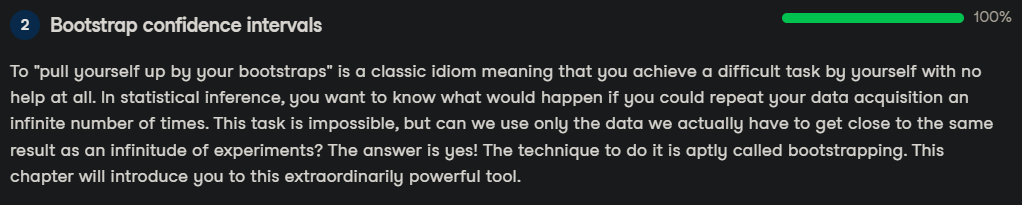

In [2]:
from IPython import display

display.Image("h2_dc.png")

---
## Problem 2

In [3]:
#Execute this cell to load all of the modules we'll need and define the data array.
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy import optimize

In [4]:
# generate (x,y, sigma_y) "data" 
data = np.array([[ 0.42,  0.72,  0.  ,  0.3 ,  0.15,
                   0.09,  0.19,  0.35,  0.4 ,  0.54,
                   0.42,  0.69,  0.2 ,  0.88,  0.03,
                   0.67,  0.42,  0.56,  0.14,  0.2  ],
                 [ 0.33,  0.41, -0.25,  0.01, -0.05,
                  -0.05, -0.12,  0.26,  0.29,  0.39, 
                   0.31,  0.42, -0.01,  0.58, -0.2 ,
                   0.52,  0.15,  0.32, -0.13, -0.09 ],
                 [ 0.1 ,  0.1 ,  0.1 ,  0.1 ,  0.1 ,
                   0.1 ,  0.1 ,  0.1 ,  0.1 ,  0.1 ,
                   0.1 ,  0.1 ,  0.1 ,  0.1 ,  0.1 ,
                   0.1 ,  0.1 ,  0.1 ,  0.1 ,  0.1  ]])

In [5]:
#Functions to do a polynomial fit, compute the likelihood, and determine the best-fit parameters.

#I mostly just want you to run this cell, but see if you can understand what is going on.
#Add TWO lines of comments showing that you at least sort of understand.

def polynomial_fit(theta, x):
    """Polynomial model of degree (len(theta) - 1)"""
    # For a polynomial with order 1, this gives theta_0 + theta_1*x
    # For a polynomial with order 2, this gives theta_0 + theta_1*x + theta_2*x^2, etc.
    return sum(t * x ** n for (n, t) in enumerate(theta))

# compute the data log-likelihood given a model
def logL(theta, data, model=polynomial_fit):
    """Gaussian log-likelihood of the model at theta"""
    x, y, sigma_y = data
    y_fit = model(theta, x)
    return sum(stats.norm.logpdf(*args) for args in zip(y, y_fit, sigma_y))

# a direct optimization approach is used to get best model 
# parameters (which minimize -logL)
def best_theta(degree, model=polynomial_fit, data=data):
    theta_0 = (degree + 1) * [0]
    neg_logL = lambda theta: -logL(theta, data, model)
    return optimize.fmin_bfgs(neg_logL, theta_0, disp=False)

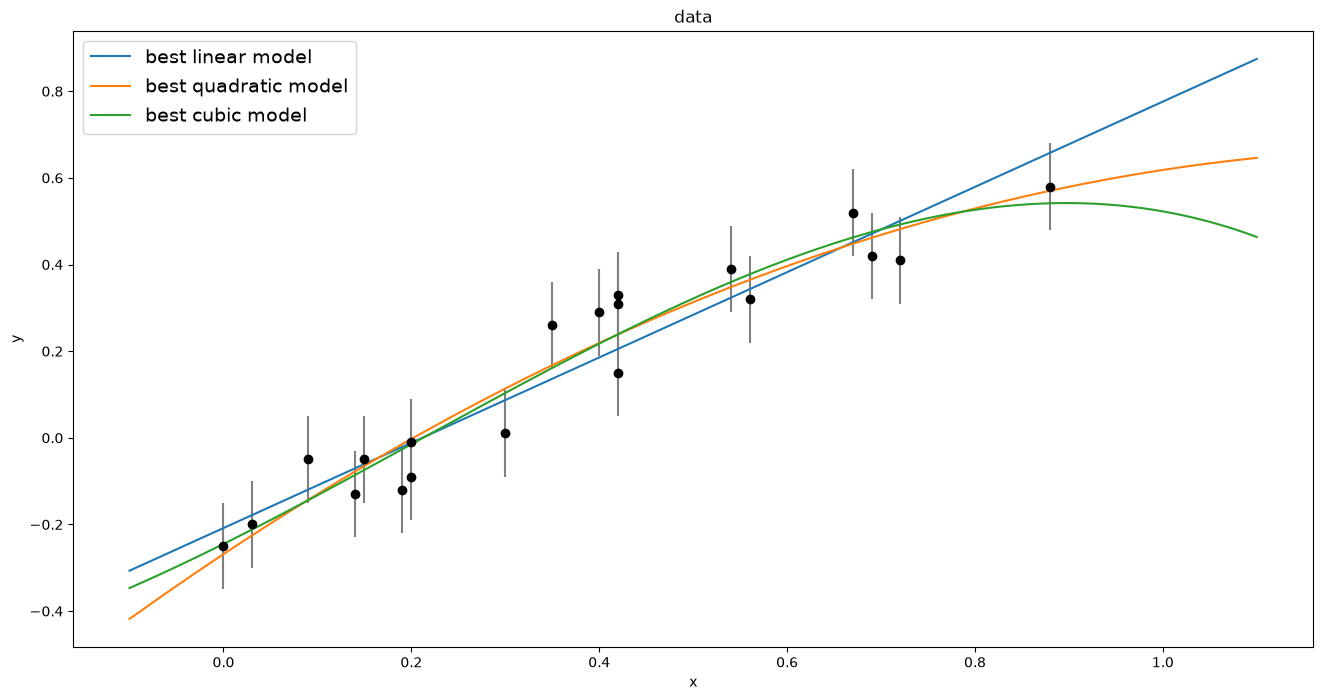

In [6]:
#Execute this cell.

#Again, I mostly just want you to run this cell, but see if you can understand what is going on.
#Add TWO lines of comments showing that you at least sort of understand.

x, y, sigma_y = data                                # setting the x, y and the sigma values from the data array
Ndata = x.size                                      # Ndata represents the number of data points 

# get best-fit parameters for linear, quadratic and cubic models
theta1 = best_theta(1, data=data)
theta2 = best_theta(2, data=data)
theta3 = best_theta(3, data=data)
# generate best fit lines on a fine grid 
xgrid = np.linspace(-0.1, 1.1, 1000)
yfit1 = polynomial_fit(theta1, xgrid)               # linear fit
yfit2 = polynomial_fit(theta2, xgrid)               # quadratic fit
yfit3 = polynomial_fit(theta3, xgrid)               # cubic fit

# plot 
fig, ax = plt.subplots(figsize=(16, 8))
ax.errorbar(x, y, sigma_y, fmt='ok', ecolor='gray')
ax.plot(xgrid, yfit1, label='best linear model')
ax.plot(xgrid, yfit2, label='best quadratic model')
ax.plot(xgrid, yfit3, label='best cubic model')
ax.legend(loc='best', fontsize=14)
ax.set(xlabel='x', ylabel='y', title='data');

In [7]:
#Complete and execute this cell to compute chi2: sum{[(y-yfit)/sigma_y]^2} 
chi21 = np.sum(((y-polynomial_fit(theta1, x))/sigma_y)**2) 
chi22 = np.sum(((y-polynomial_fit(theta2, x))/sigma_y)**2) 
chi23 = np.sum(((y-polynomial_fit(theta3, x))/sigma_y)**2) 
# normalize by the number of degrees of freedom
# the number of fitted parameters is 2, 3, 4
chi2dof1 = chi21/(Ndata - 2)
chi2dof2 = chi22/(Ndata - 3)
chi2dof3 = chi23/(Ndata - 4)

print("CHI2:")
print('   best linear model:', chi21)
print('best quadratic model:', chi22)
print('    best cubic model:', chi23)
print("CHI2 per degree of freedom:")
print('   best linear model:', chi2dof1)
print('best quadratic model:', chi2dof2)
print('    best cubic model:', chi2dof3)

CHI2:
   best linear model: 11.499462014956965
best quadratic model: 9.291258246116401
    best cubic model: 8.979208294683978
CHI2 per degree of freedom:
   best linear model: 0.6388590008309425
best quadratic model: 0.5465446027127294
    best cubic model: 0.5612005184177487


-logL: [-11.92320019 -13.02730207 -13.18332705]
AIC: [-19.14051802 -18.55460415 -15.69998743]
BIC: [-17.85493583 -17.06740732 -14.383725  ]
[-11.92320019 -13.02730207 -13.18332705]
[-17.85493583 -17.06740732 -14.383725  ]
[-19.14051802 -18.55460415 -15.69998743]


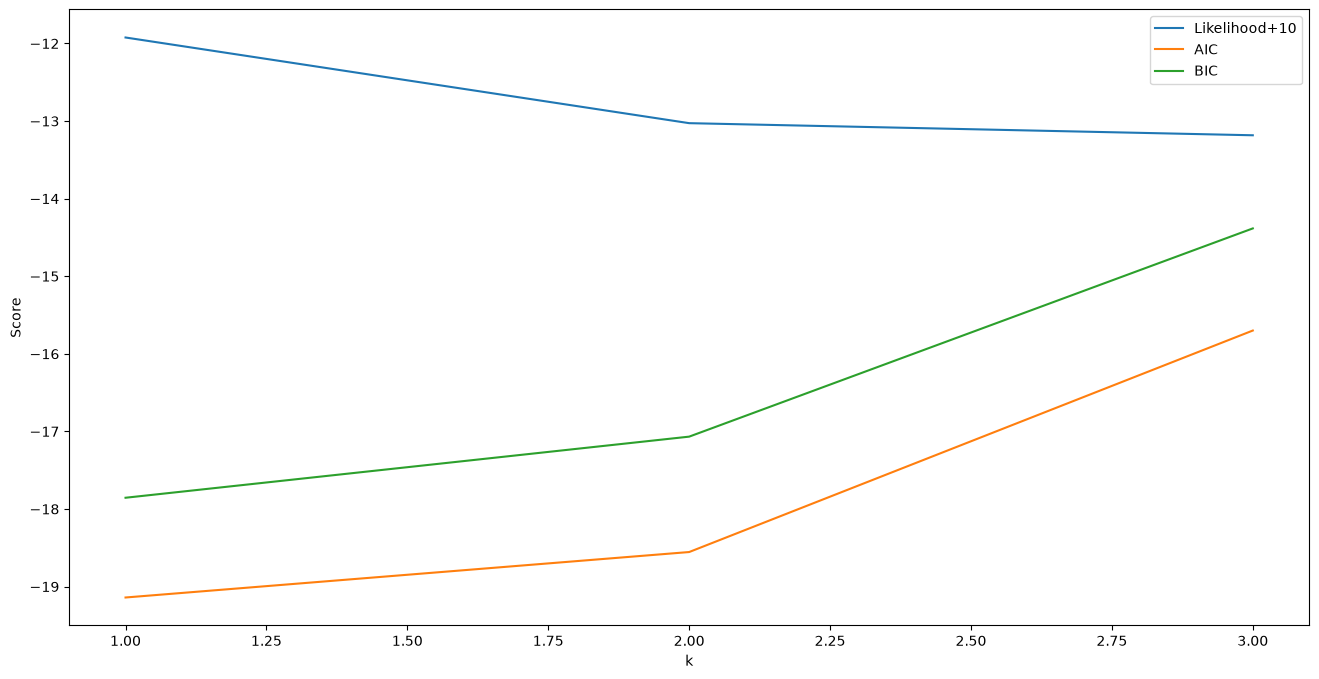

In [8]:
#Complete and execute this cell
L = [] #Array with all of the likelihood values
A = [] #Array with all of the AIC values
B = [] #Array with all of the  BICvalues
neg_LogL1 = -logL(theta1, data)+10  #+10 for plotting purposes
neg_LogL2 = -logL(theta2, data)+10
neg_LogL3 = -logL(theta3, data)+10
L = np.append(L,neg_LogL1)
L = np.append(L,neg_LogL2)
L = np.append(L,neg_LogL3)

xplot = np.arange(len(L))+1 #x values for plotting.

AIC1 = 2.*neg_LogL1 + 2.*len(theta1) + 2.*len(theta1)*(len(theta1)+1)/(len(data[0])-len(theta1)-1)
AIC2 = 2.*neg_LogL2 + 2.*len(theta2) + 2.*len(theta2)*(len(theta2)+1)/(len(data[0])-len(theta2)-1) #Complete
AIC3 = 2.*neg_LogL3 + 2.*len(theta3) + 2.*len(theta3)*(len(theta3)+1)/(len(data[0])-len(theta3)-1) #Complete
A = np.append(A,AIC1)
A = np.append(A,AIC2)
A = np.append(A,AIC3)
BIC1 = 2.*neg_LogL1 + len(theta1)*np.log(len(data[0]))
BIC2 = 2.*neg_LogL2 + len(theta2)*np.log(len(data[0])) #Complete
BIC3 = 2.*neg_LogL3 + len(theta3)*np.log(len(data[0])) #Complete
B = np.append(B,BIC1)
B = np.append(B,BIC2)
B = np.append(B,BIC3)

print("-logL:", L)
print("AIC:", A)
print("BIC:", B)


fig = plt.subplots(figsize=(16, 8))
plt.plot(xplot, L, label='Likelihood+10')
plt.plot(xplot, A, label='AIC')
plt.plot(xplot, B, label='BIC')
plt.legend()
plt.xlabel("k")
plt.ylabel("Score")
print(L)
print(B)
print(A)

---
## Problem 3

In [9]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(123)

Copy the 5 cells from lecture that are between these and modify according to the instructions.

C:\Users\sarda_hx81cfu\AppData\Local\Temp\ipykernel_22204\3855895944.py:69: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols=4, figsize=(16, 4))


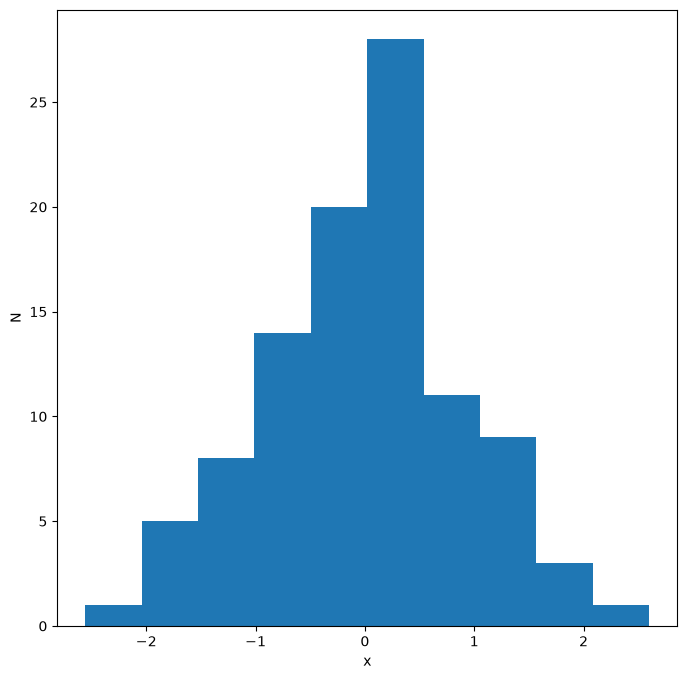

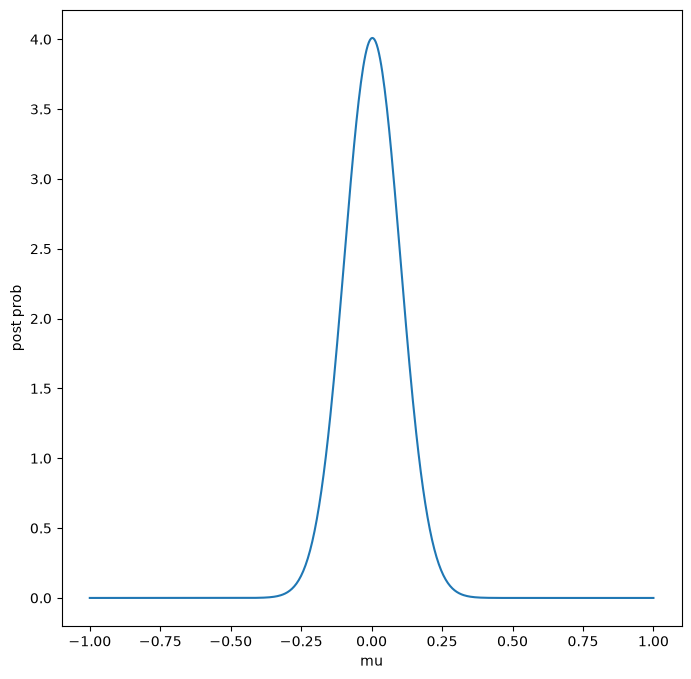

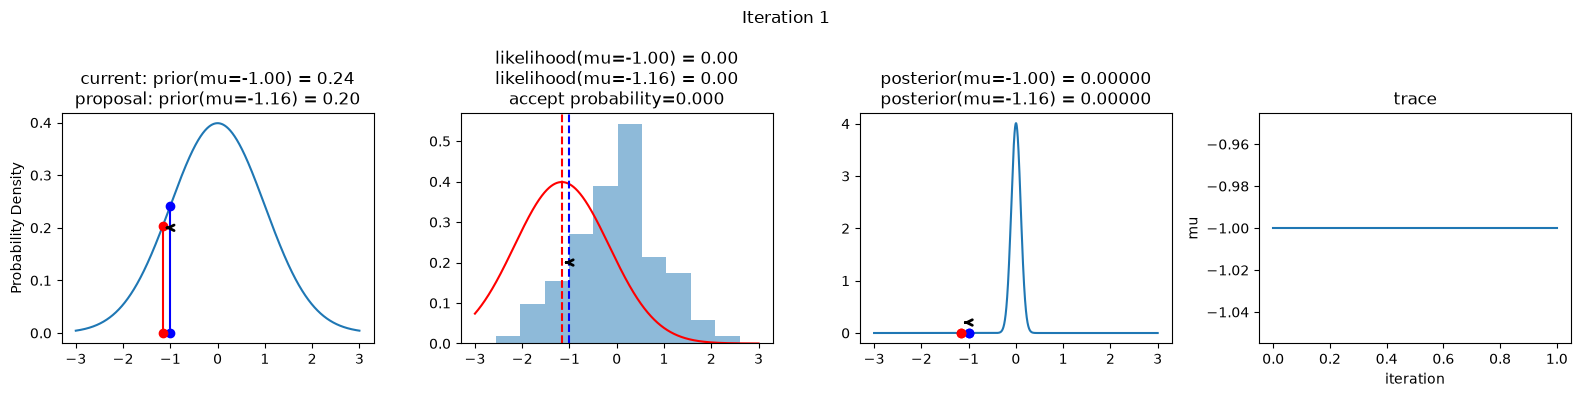

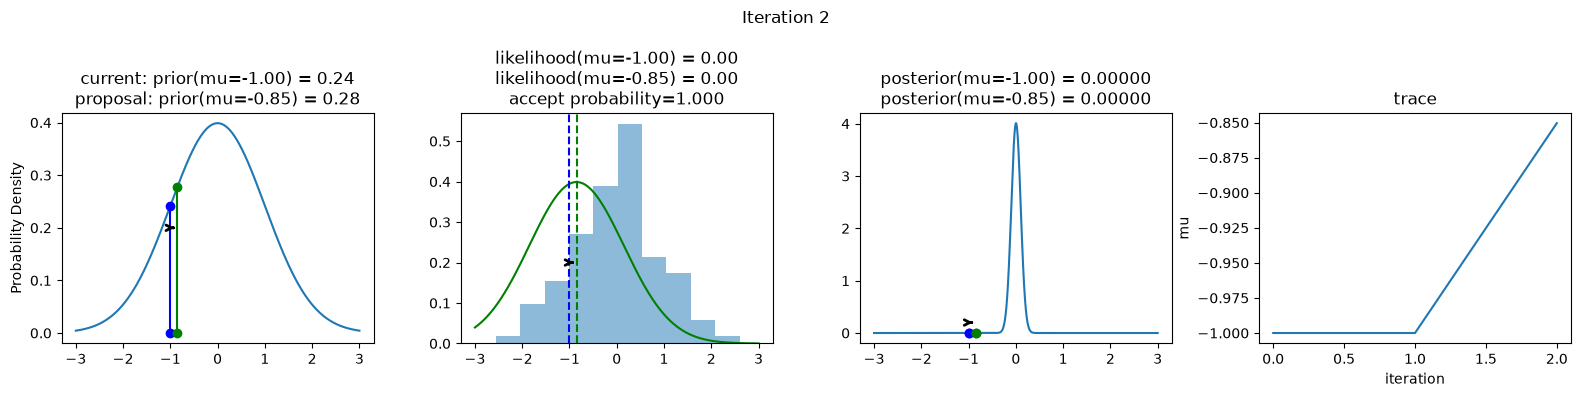

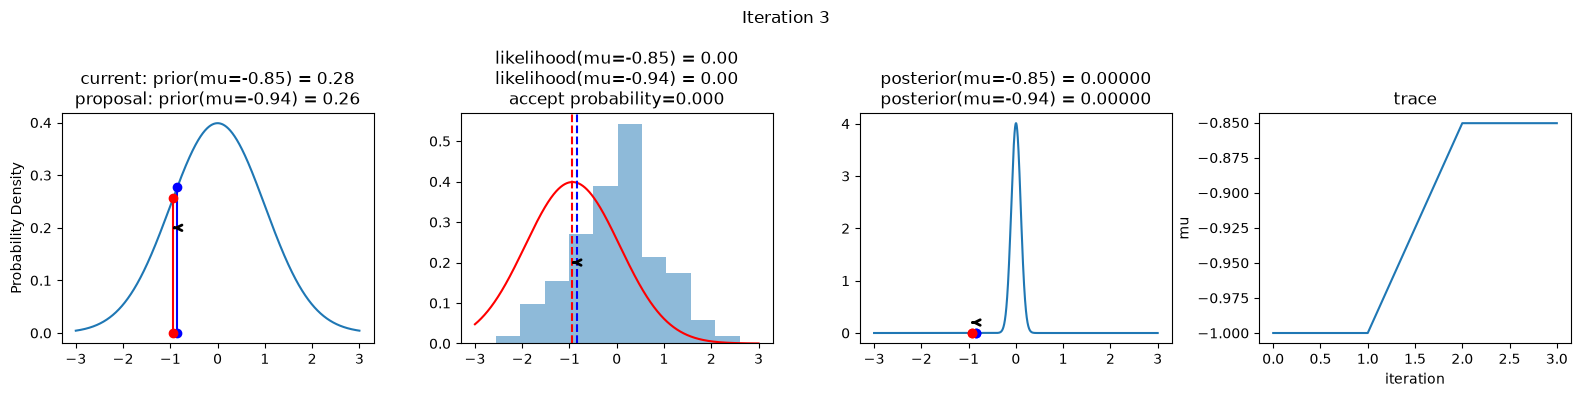

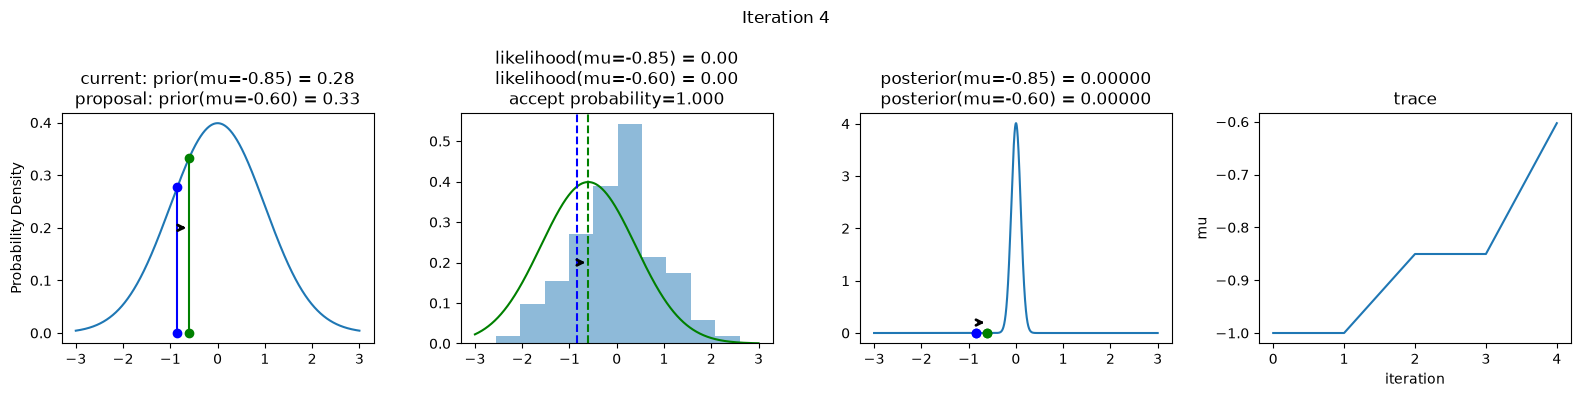

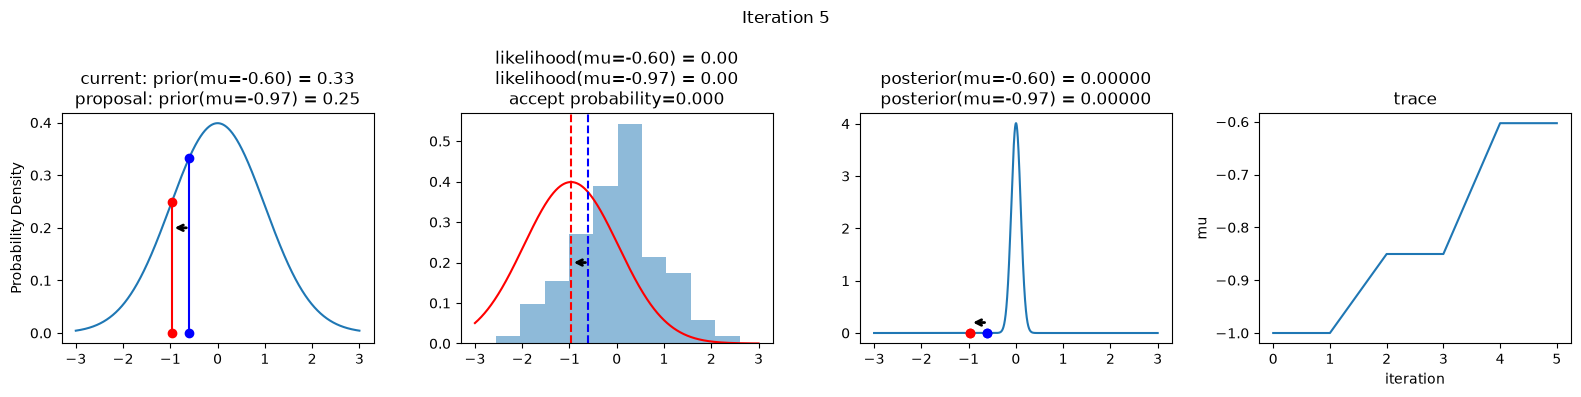

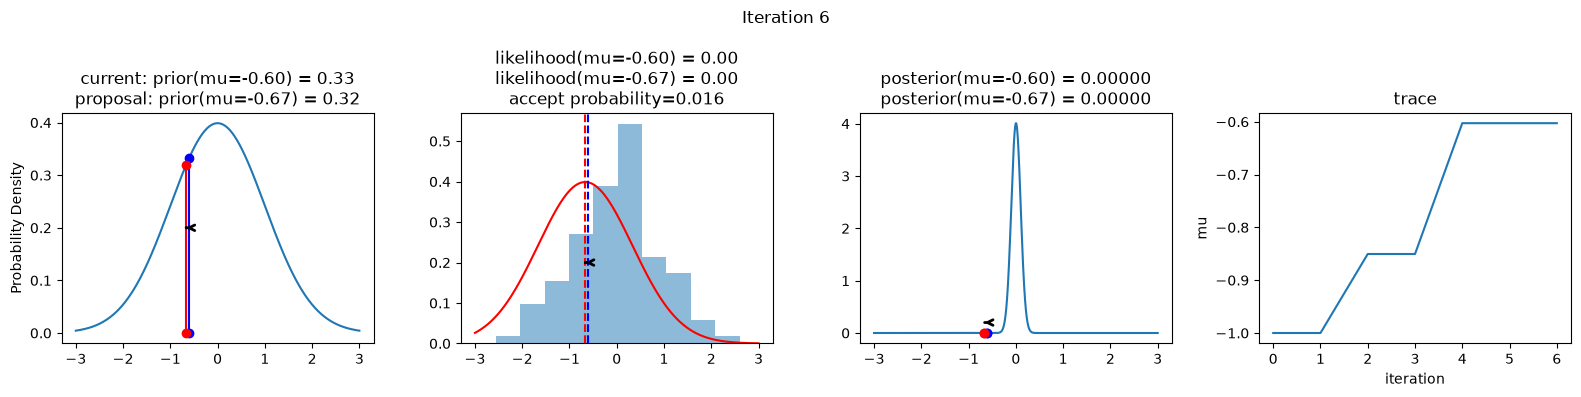

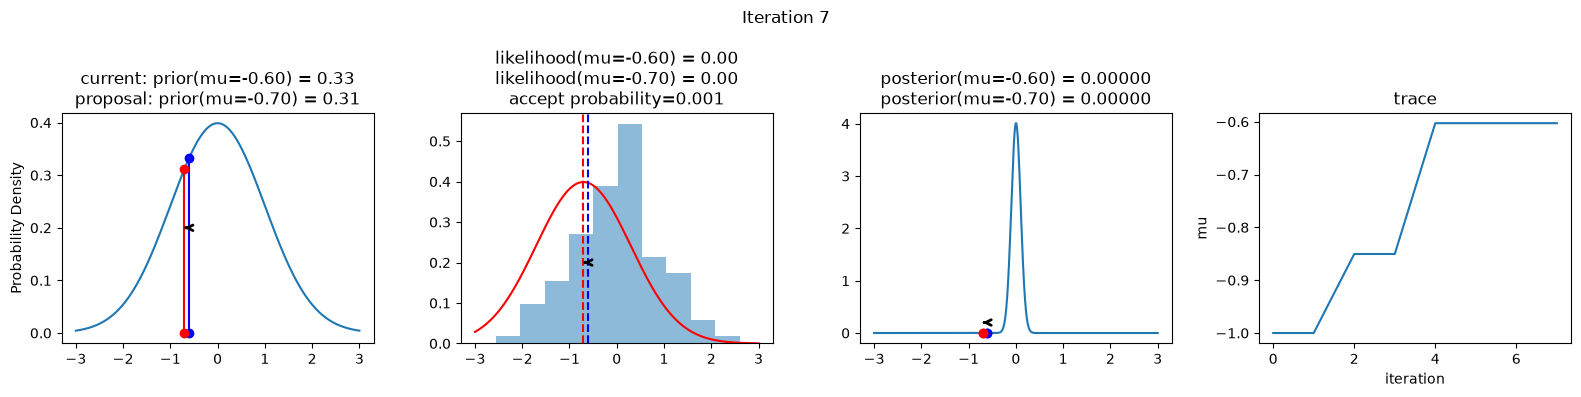

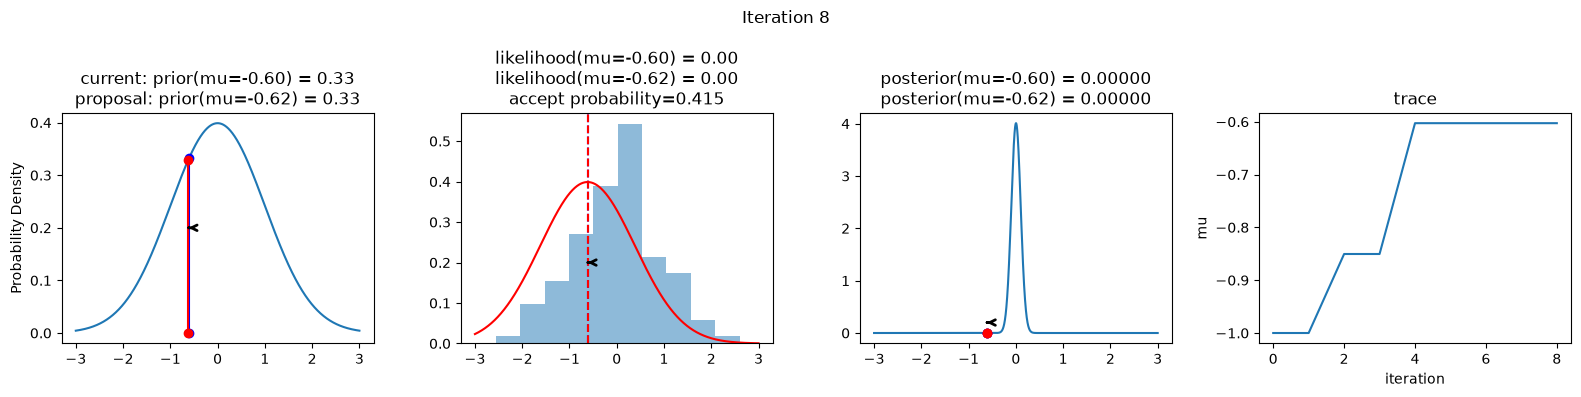

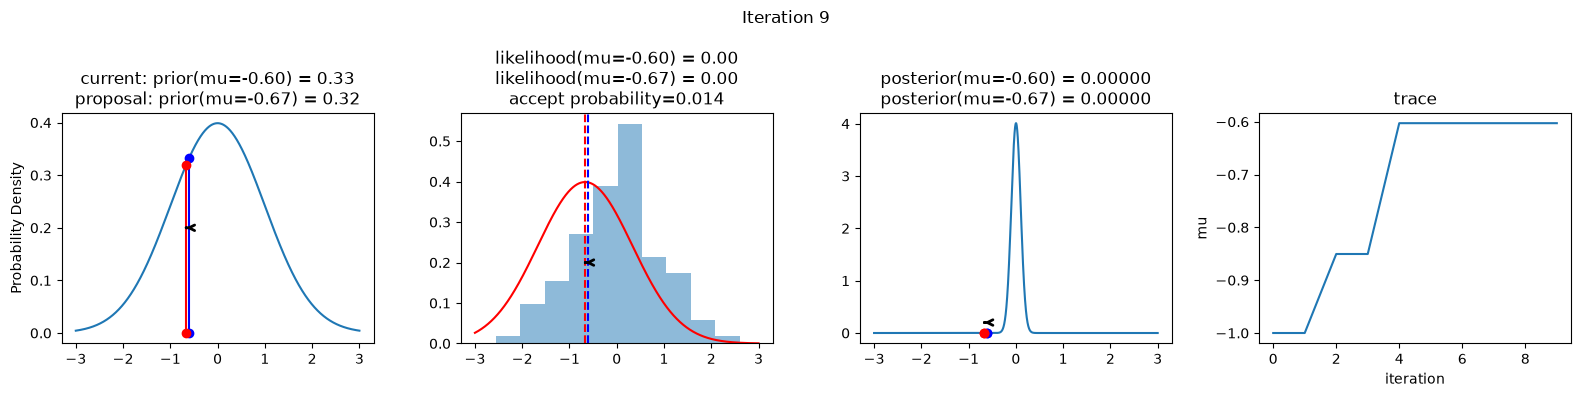

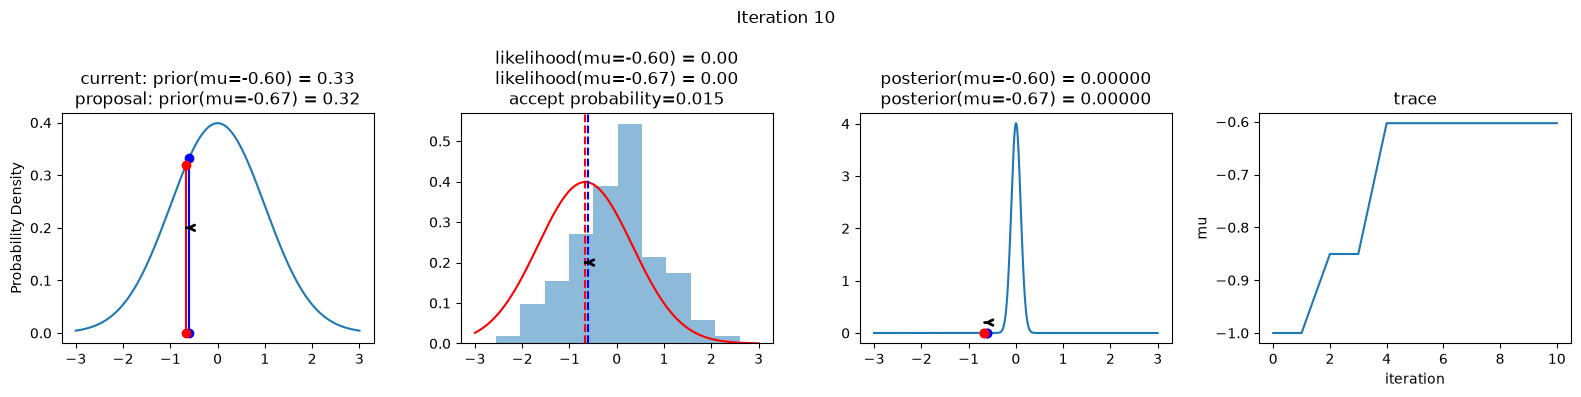

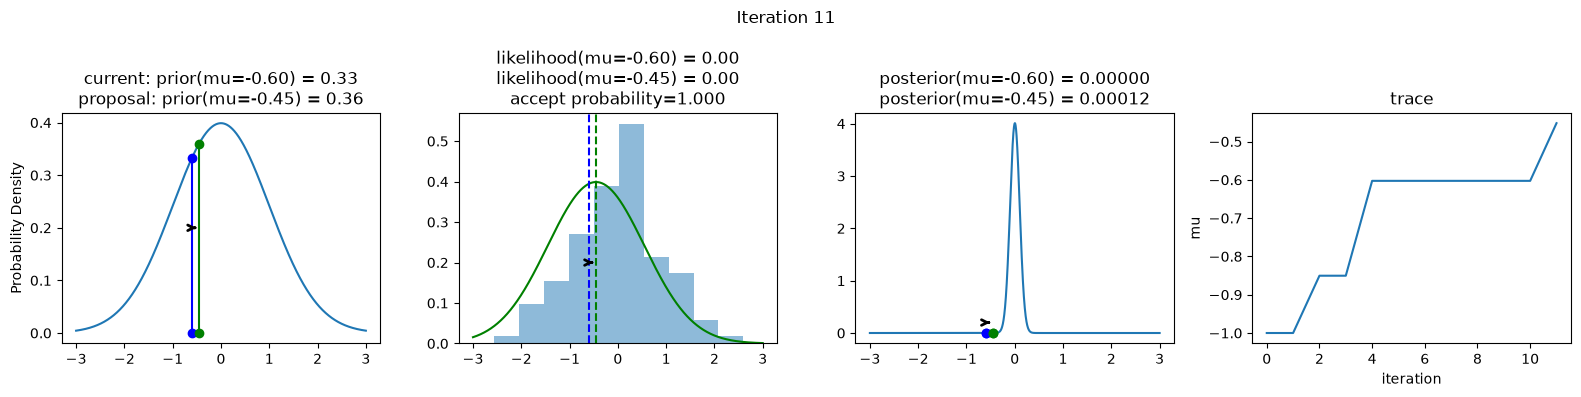

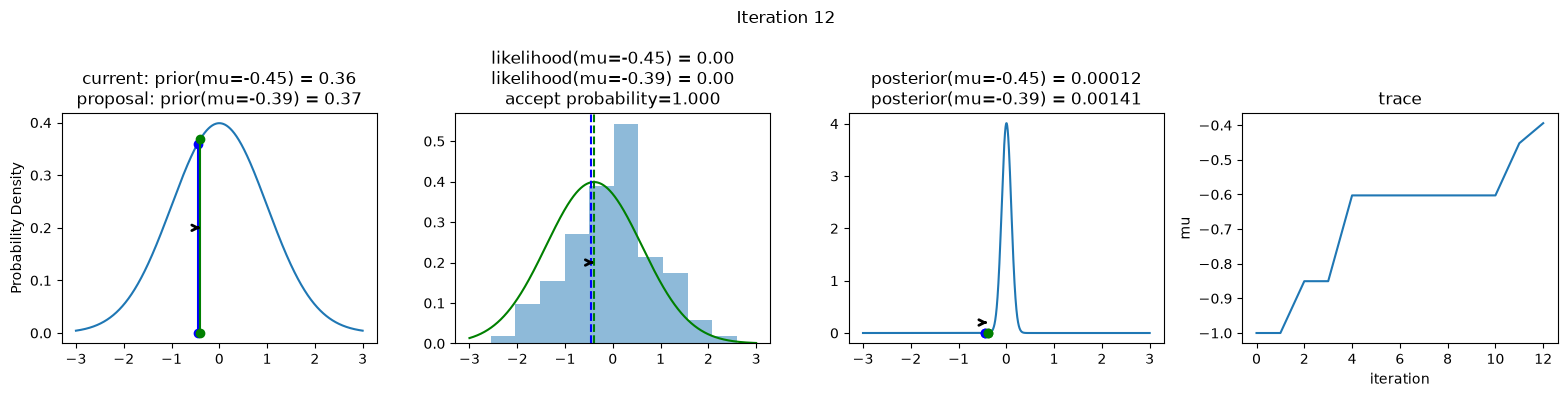

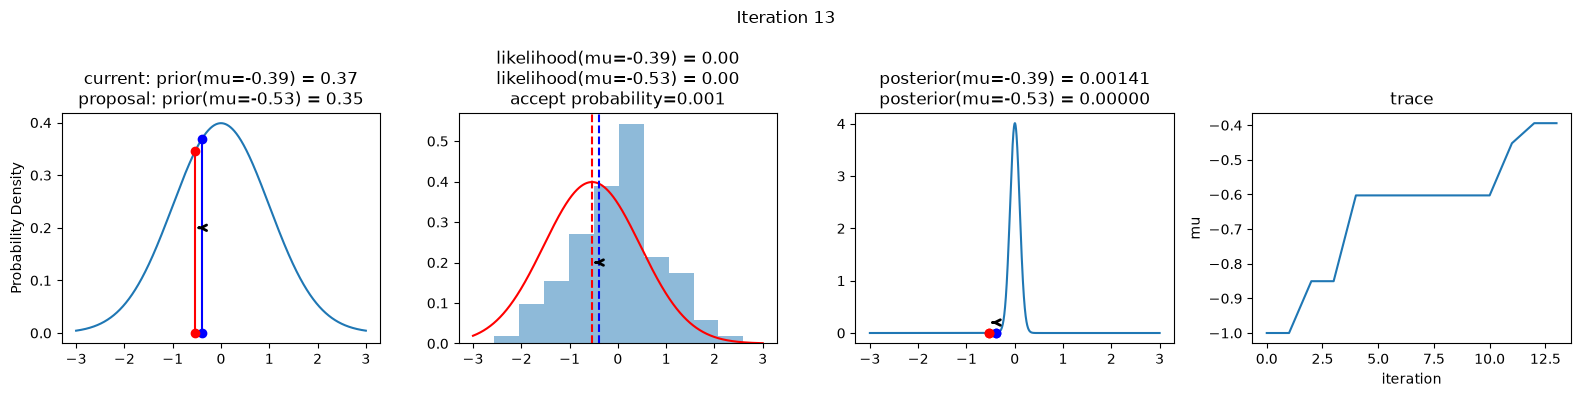

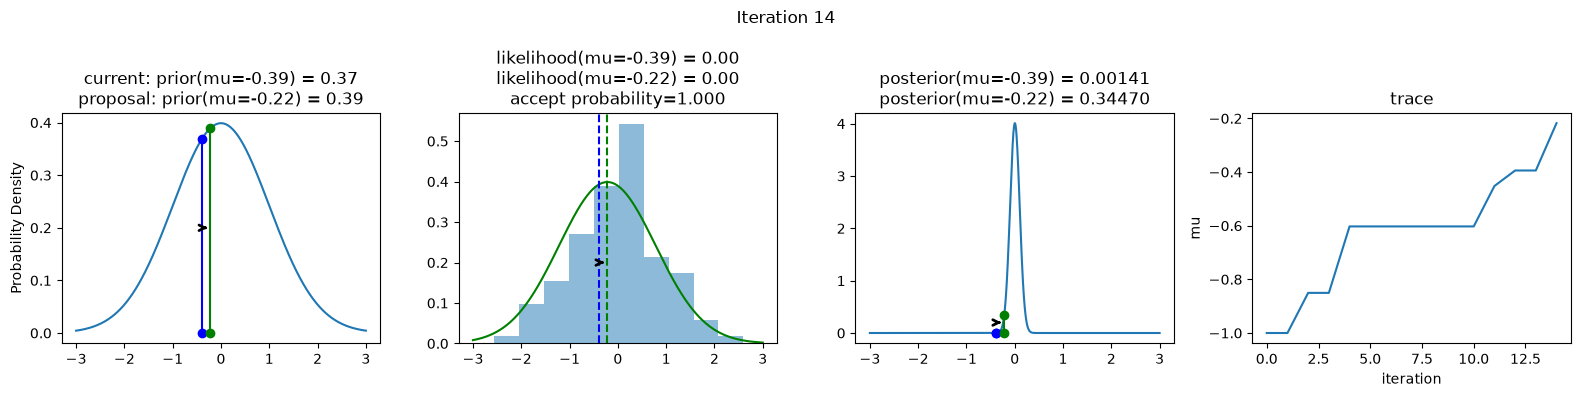

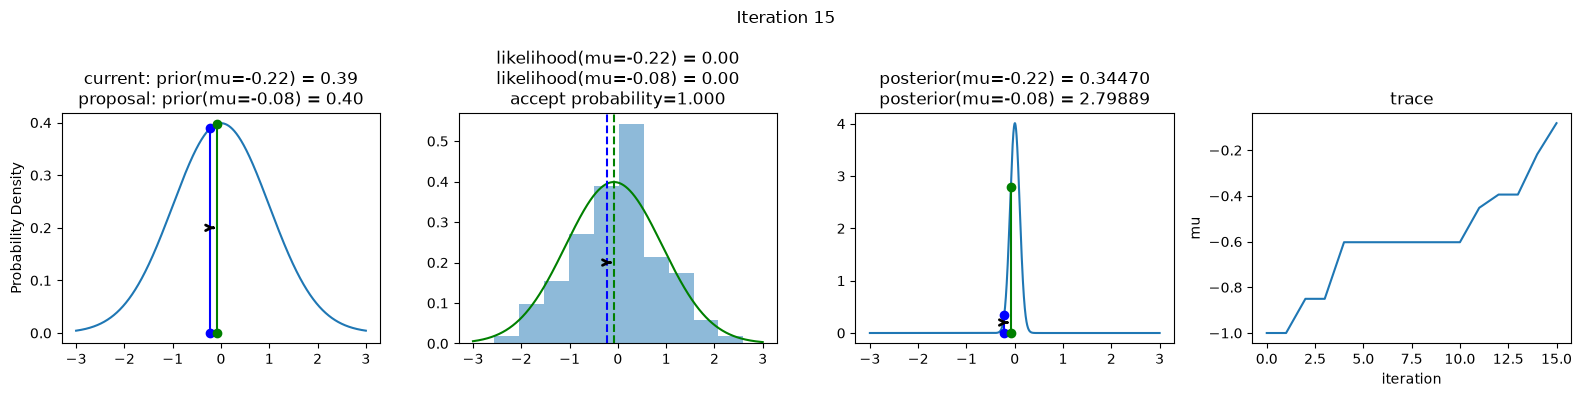

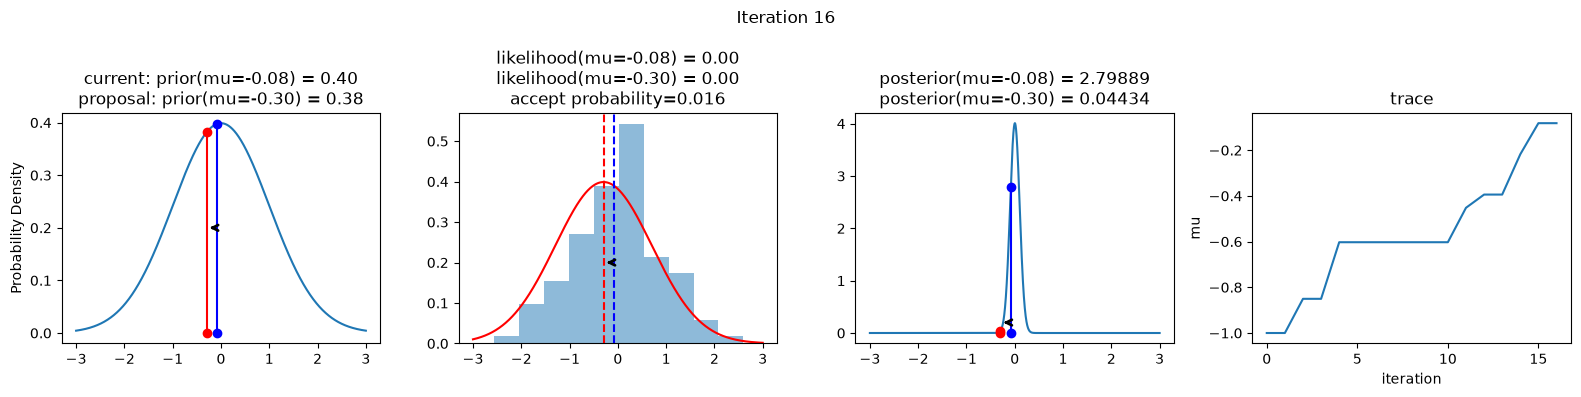

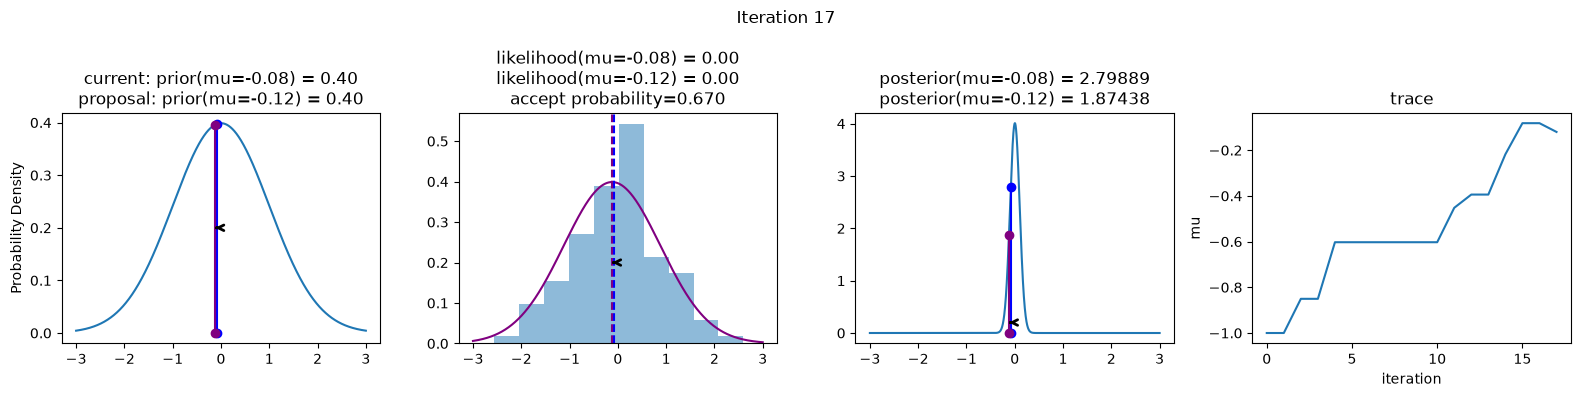

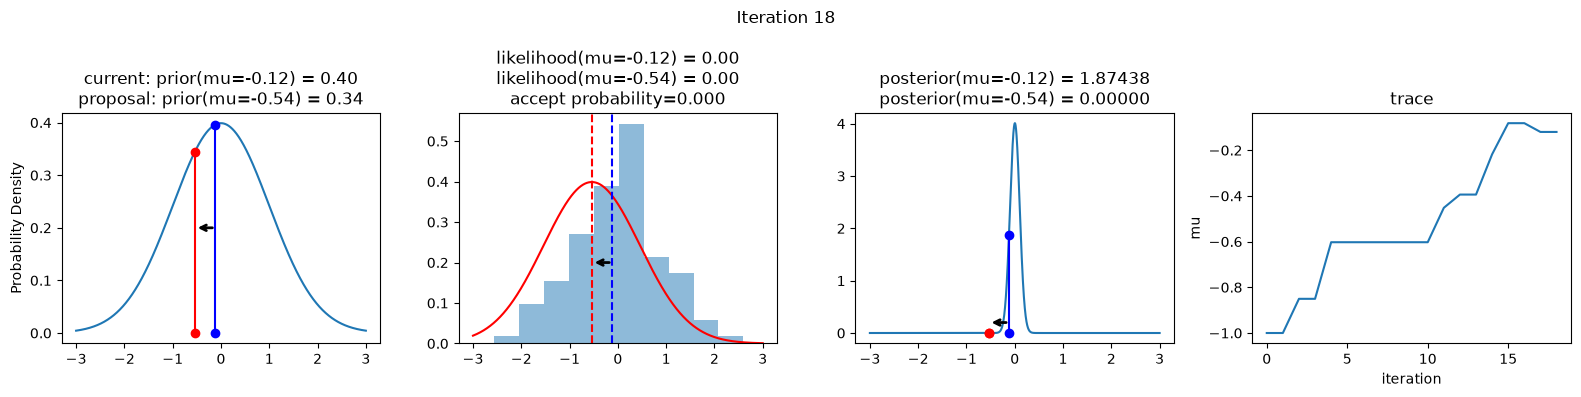

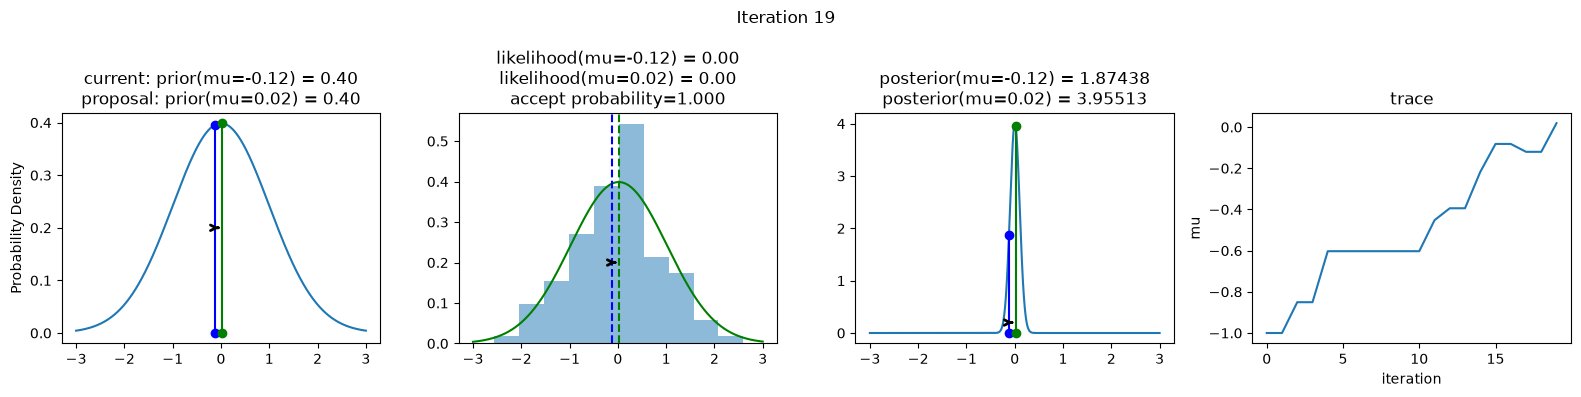

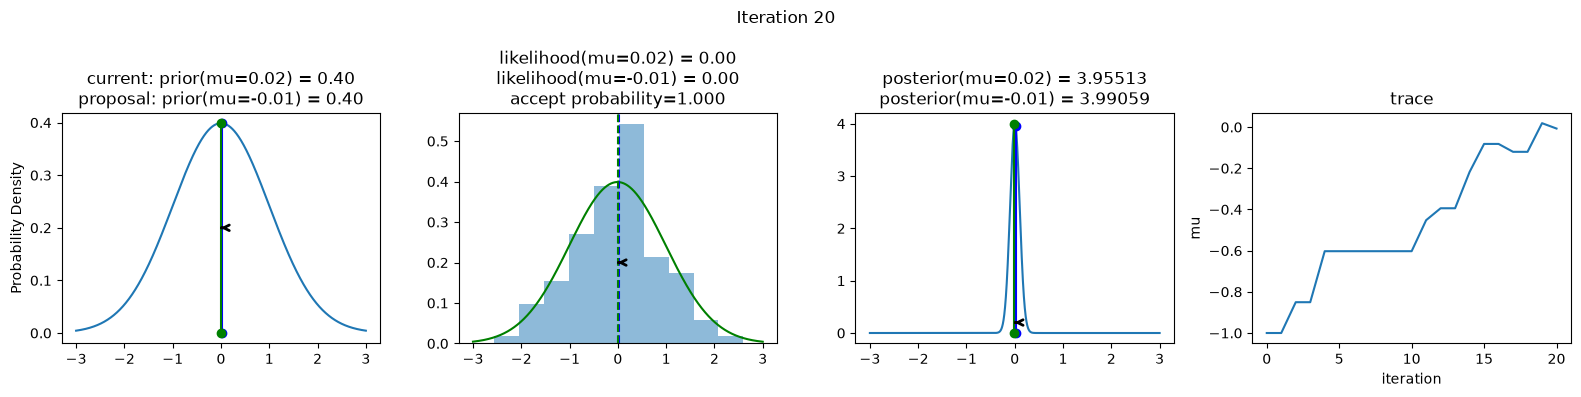

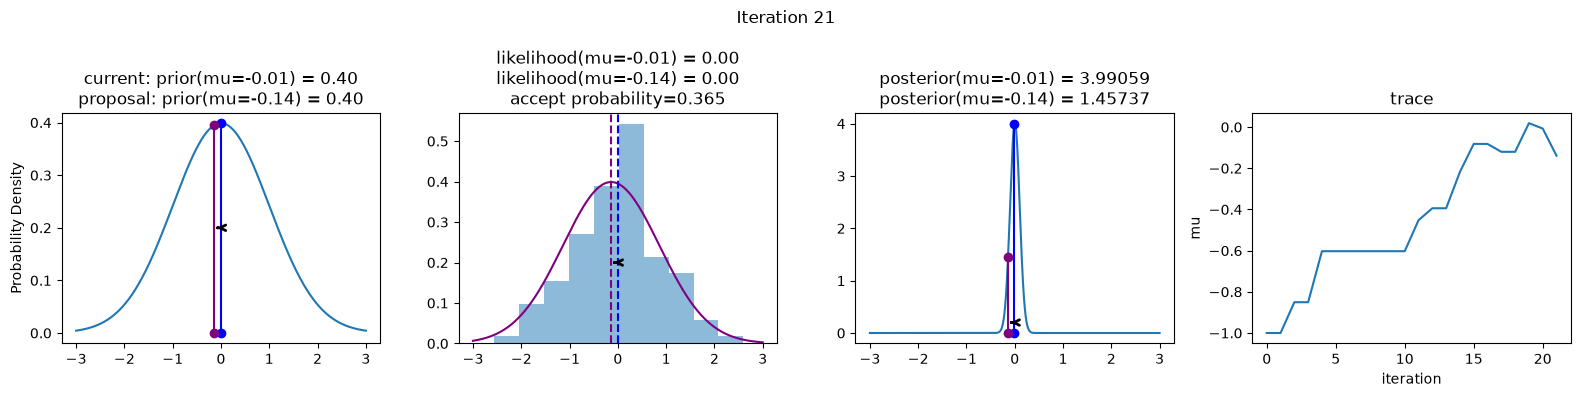

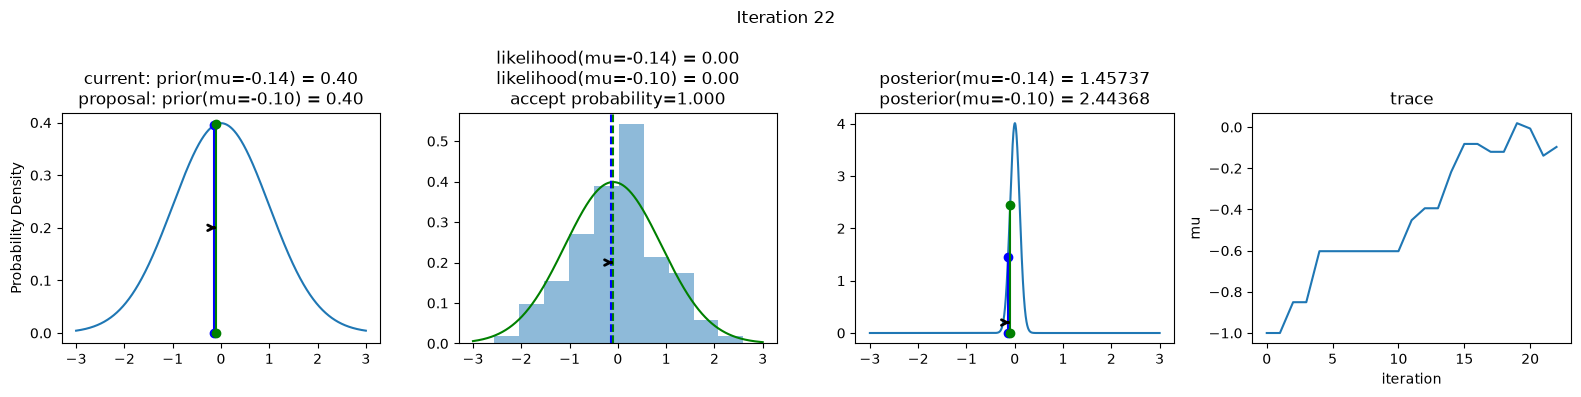

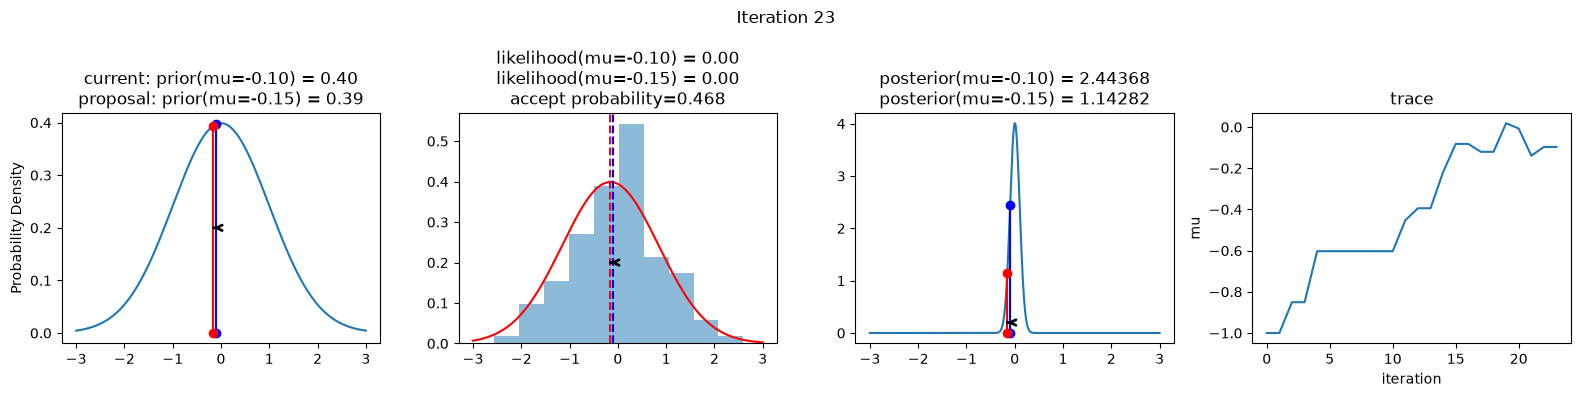

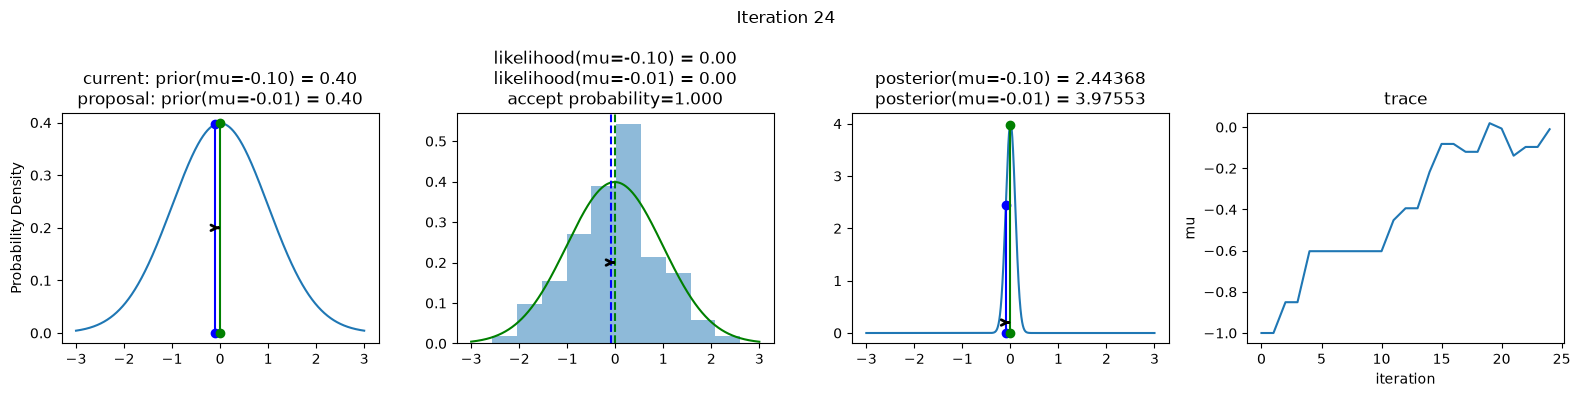

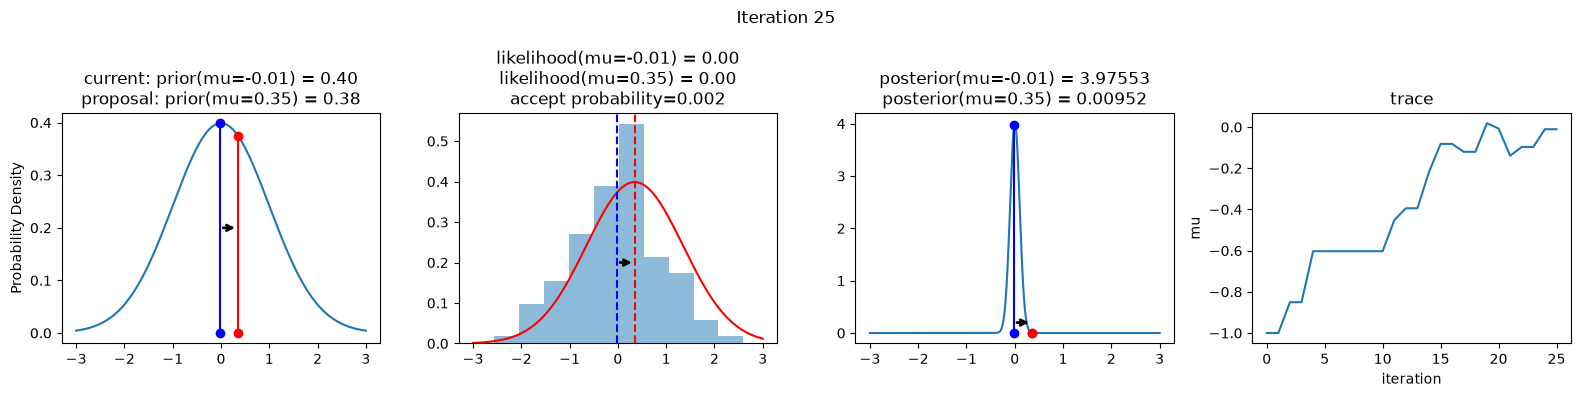

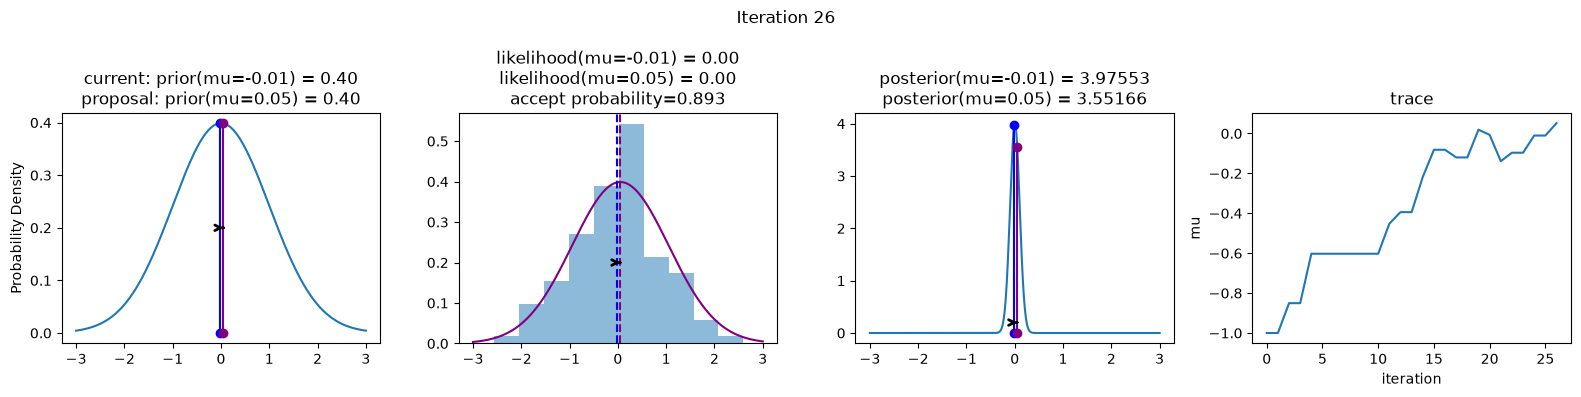

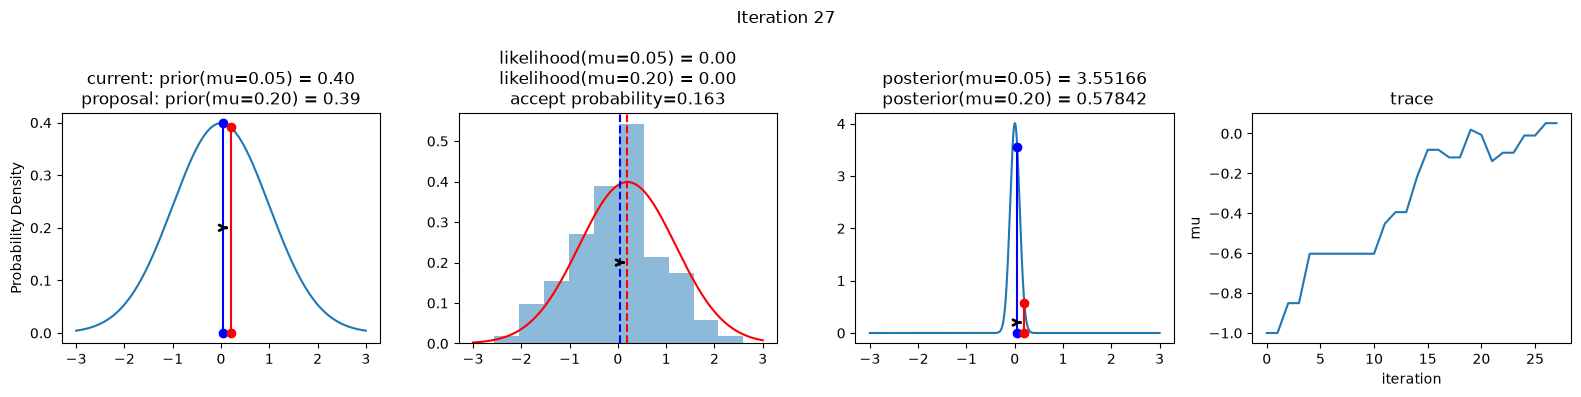

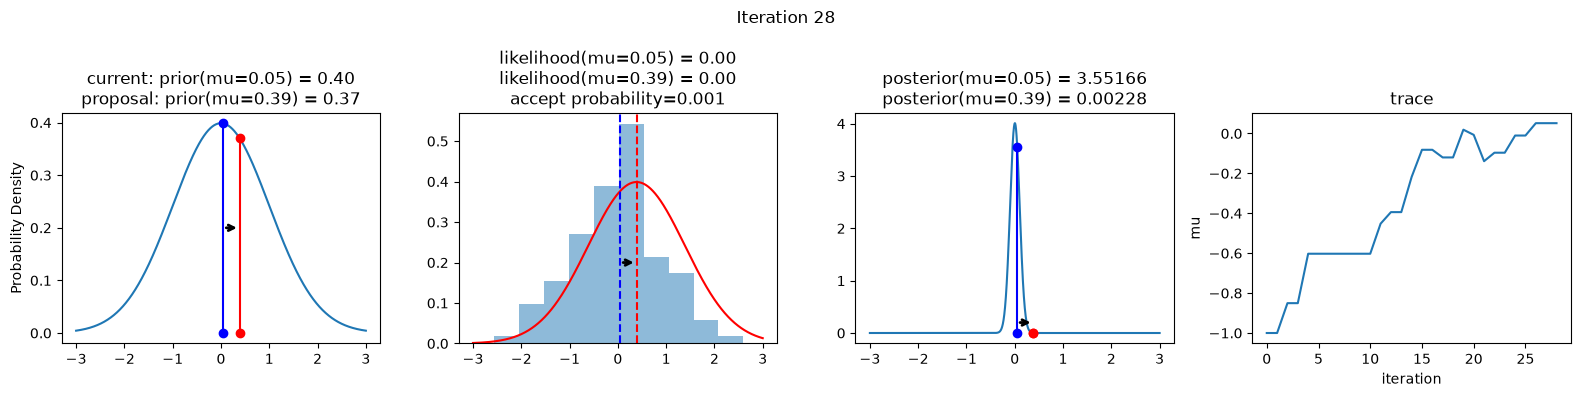

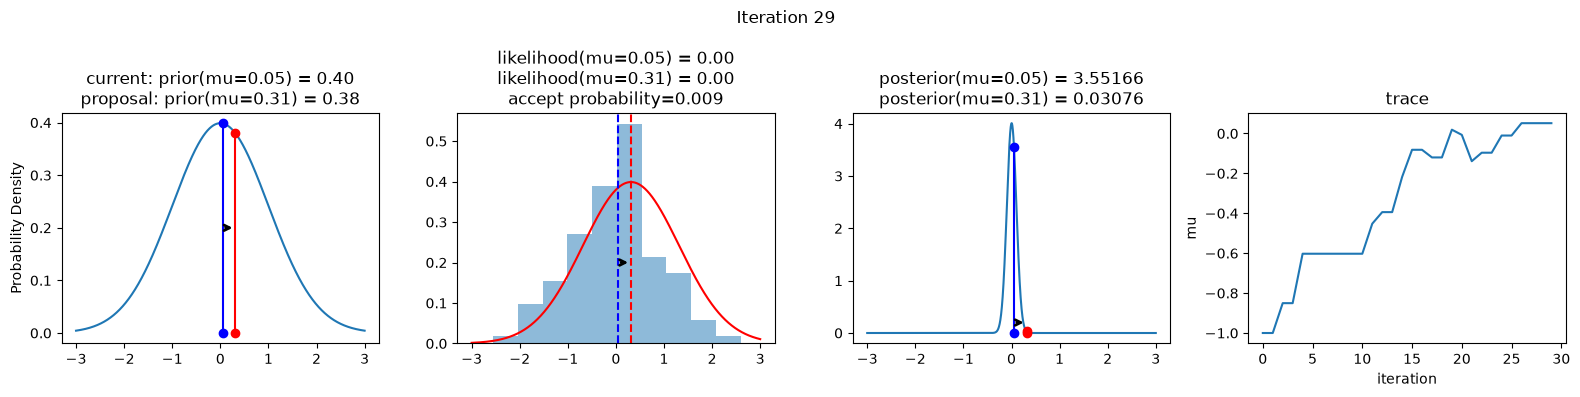

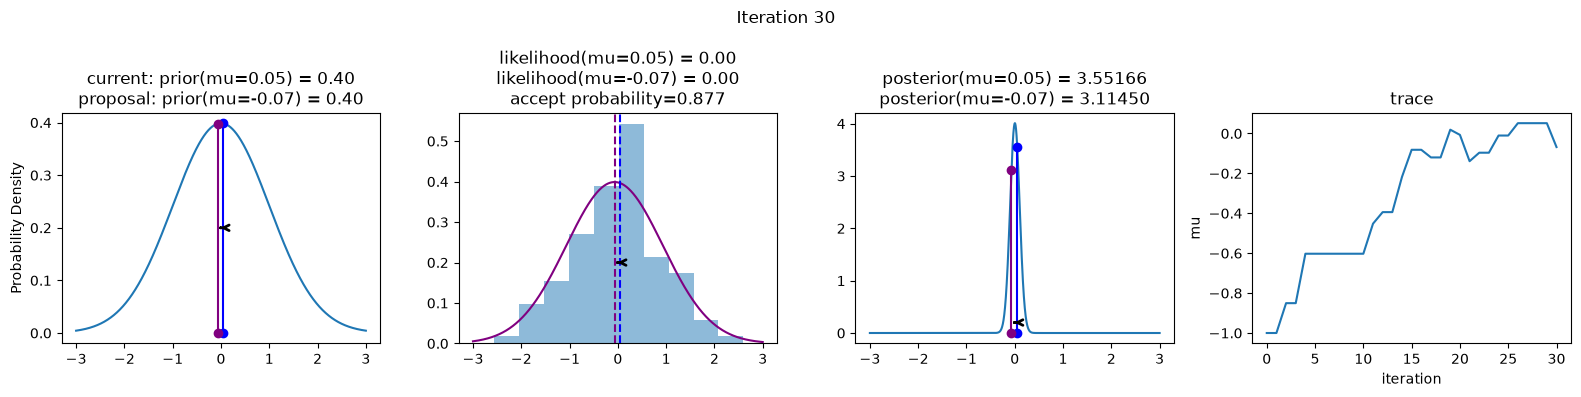

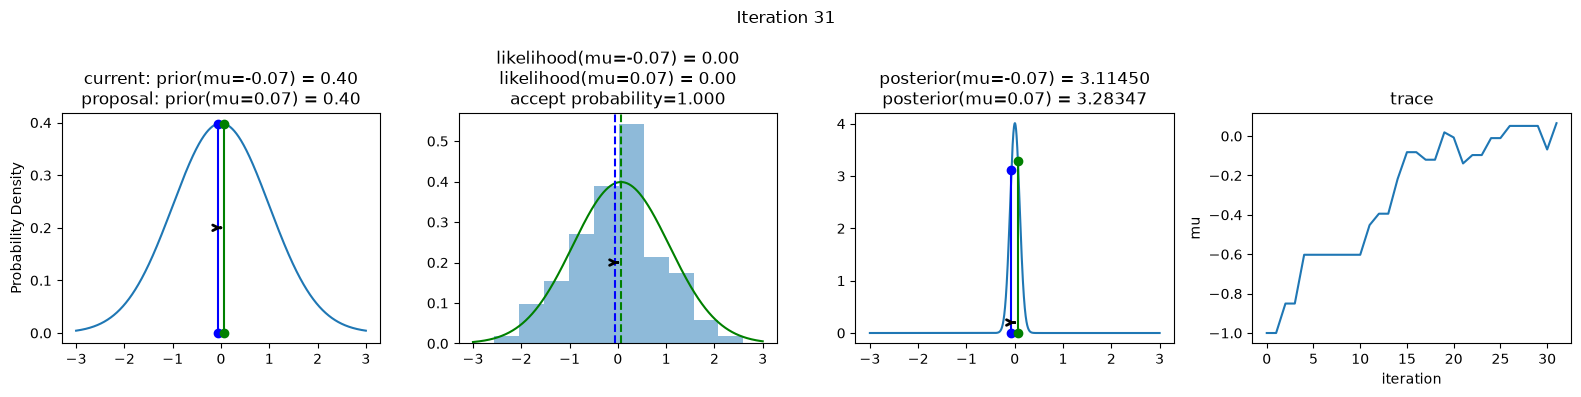

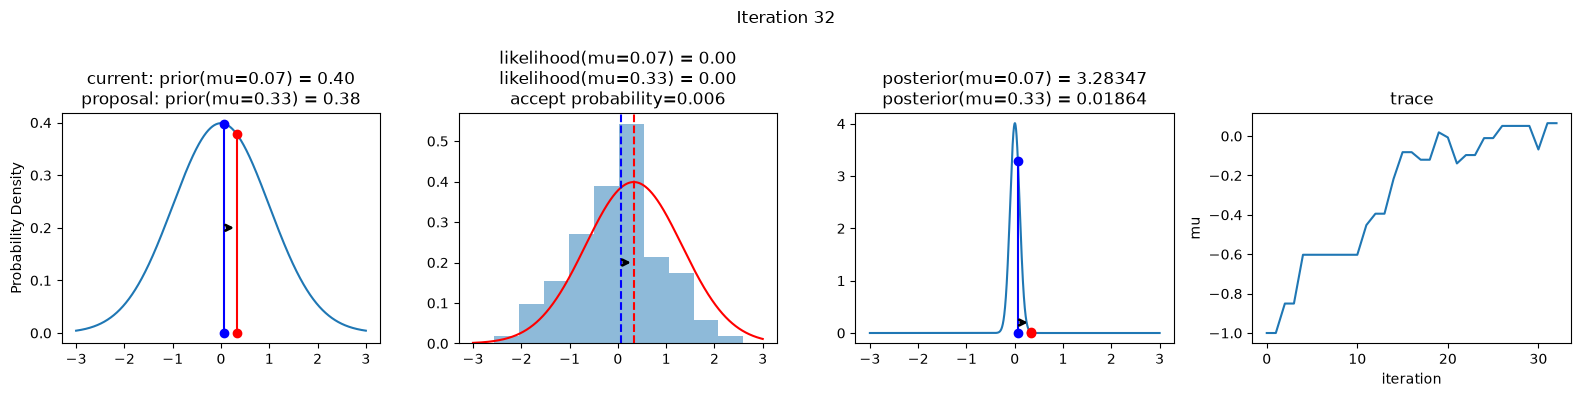

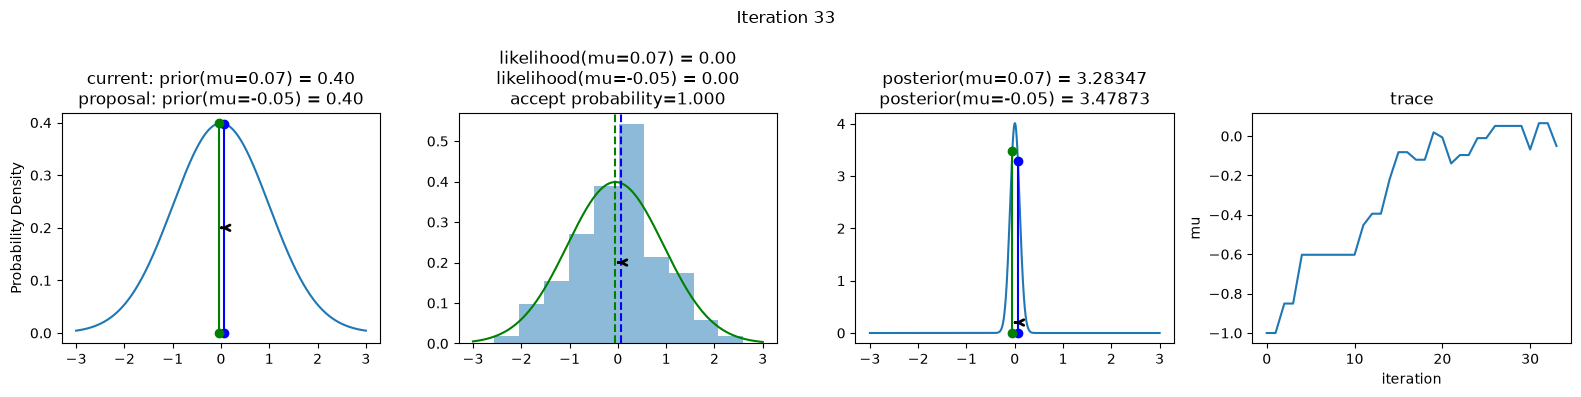

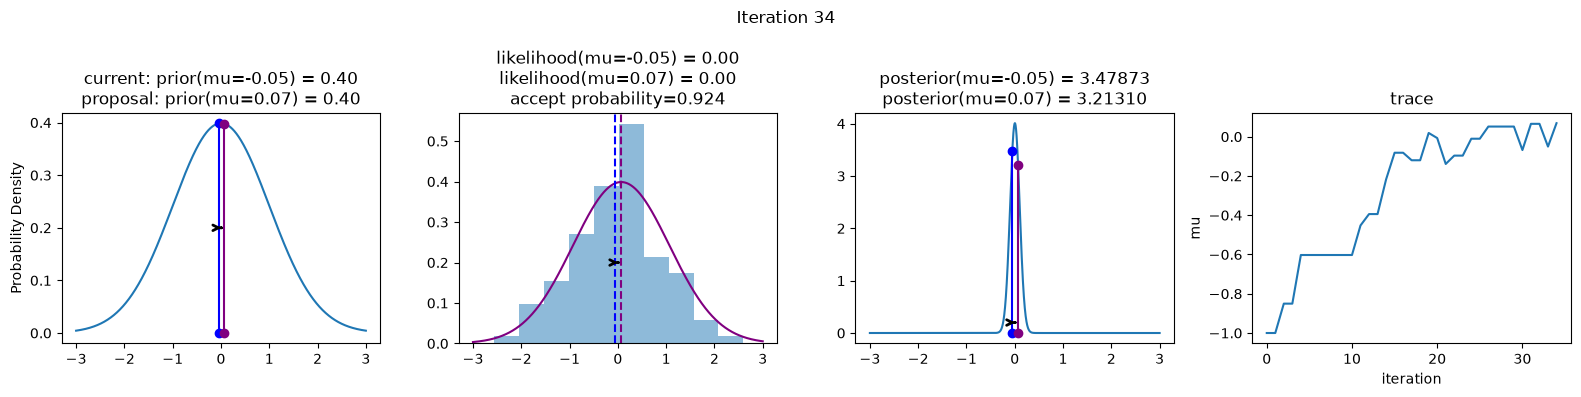

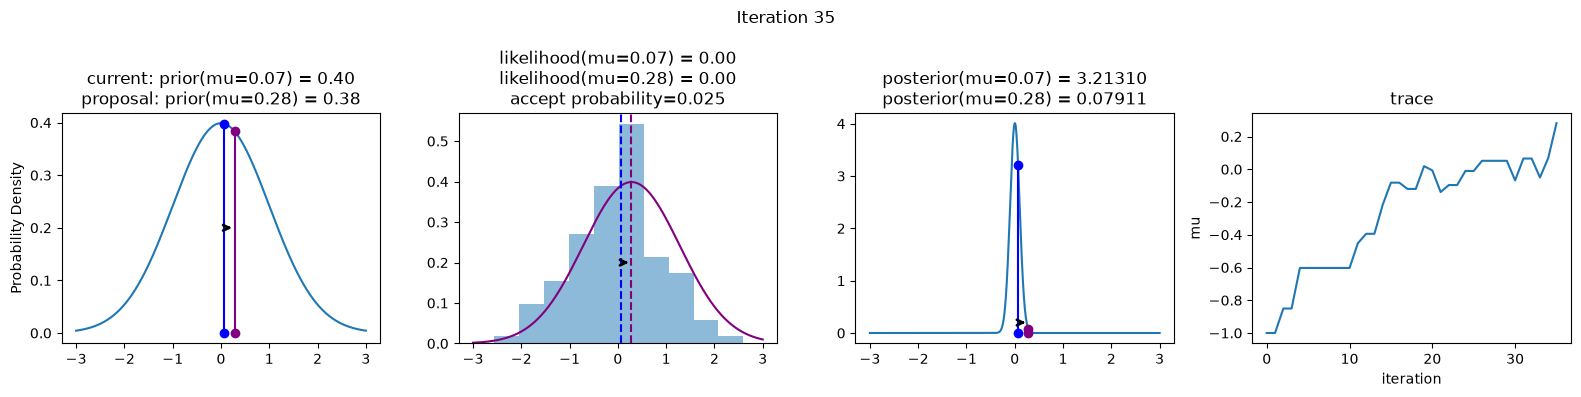

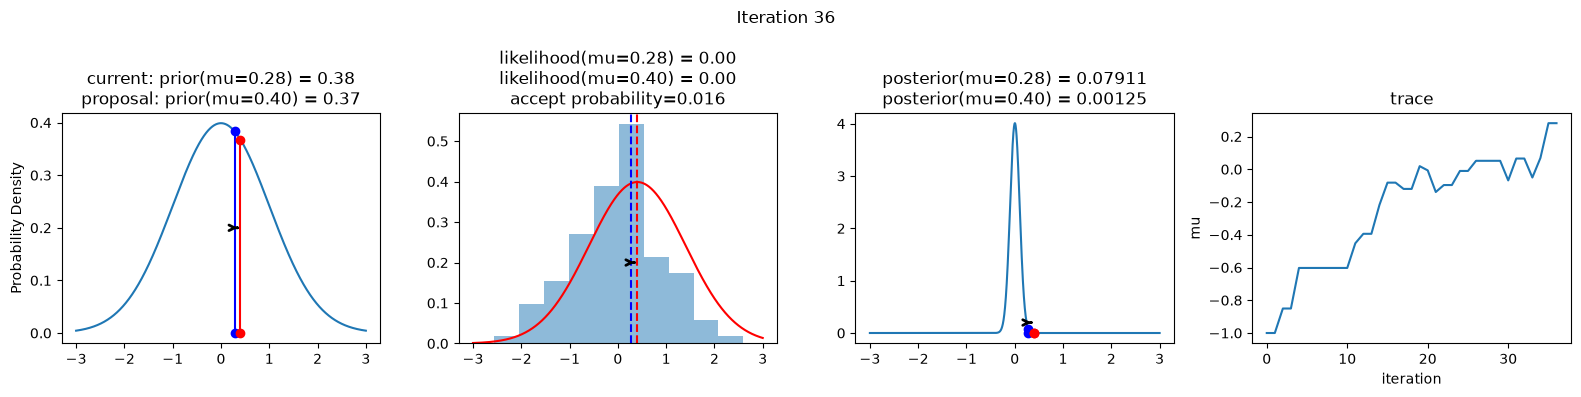

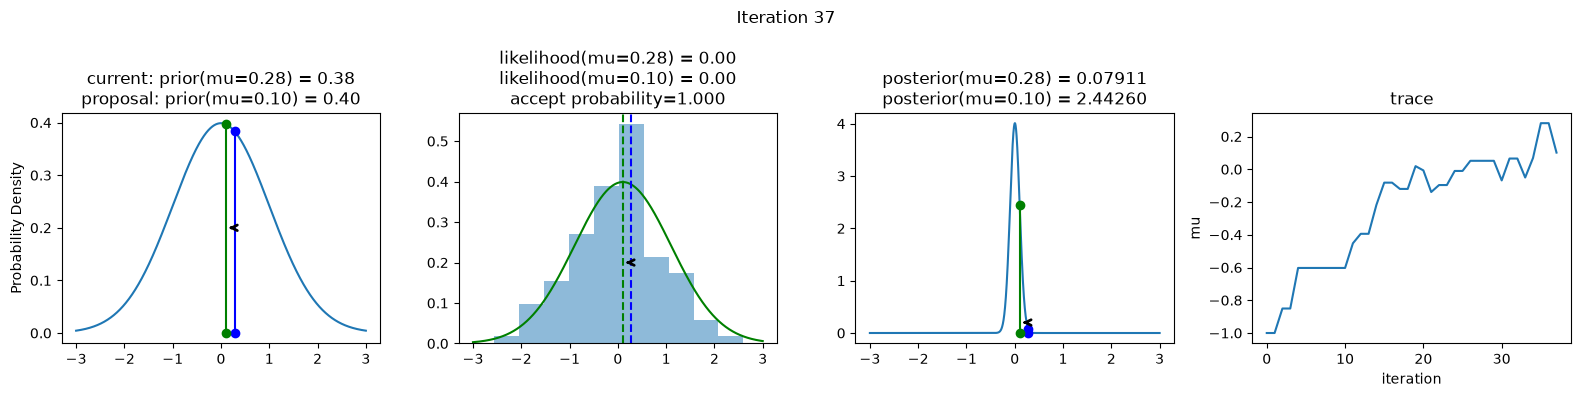

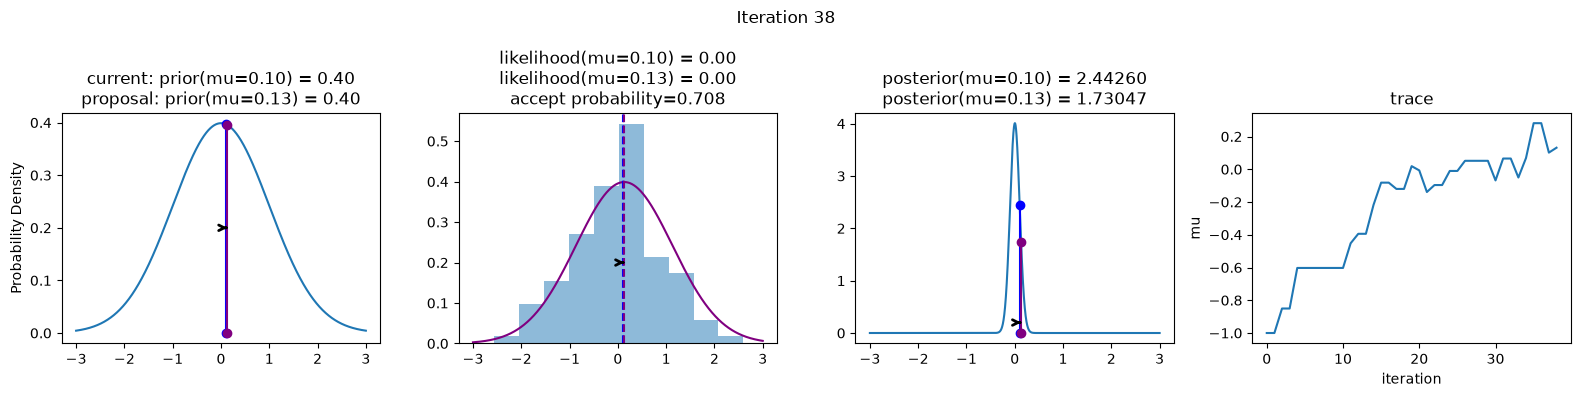

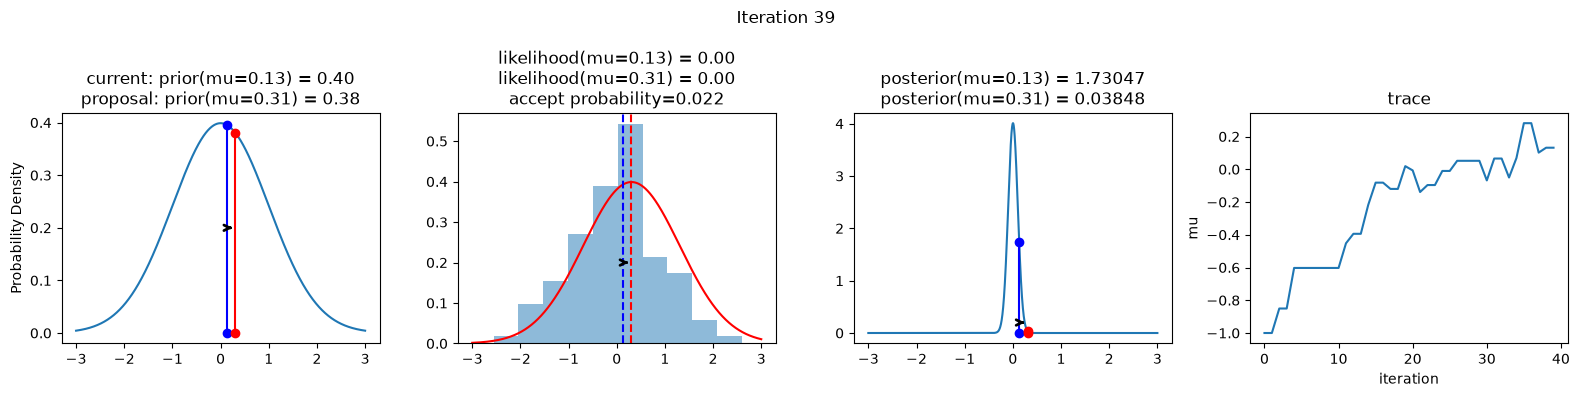

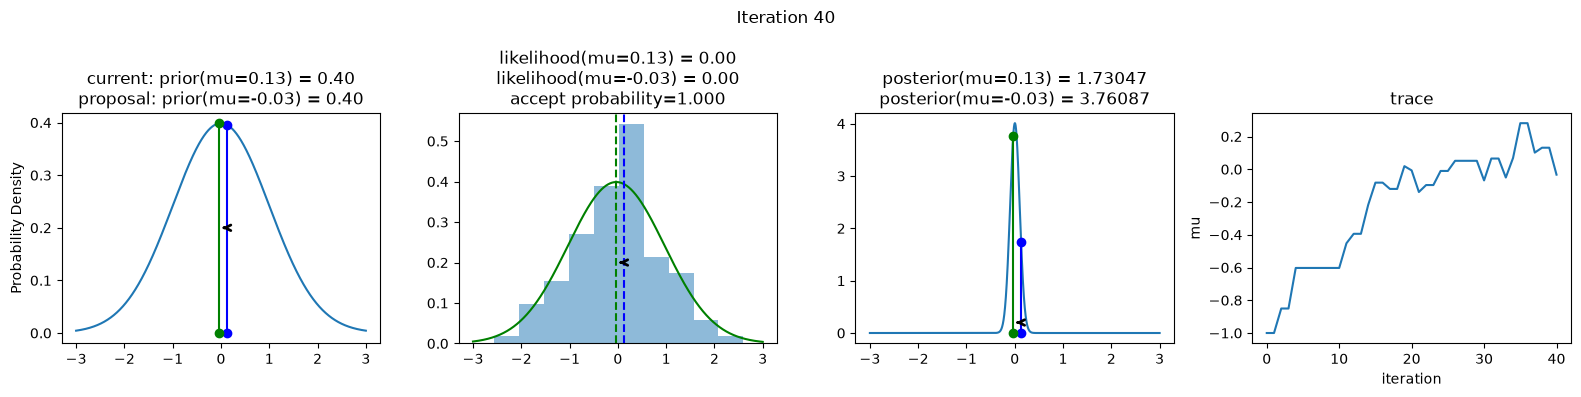

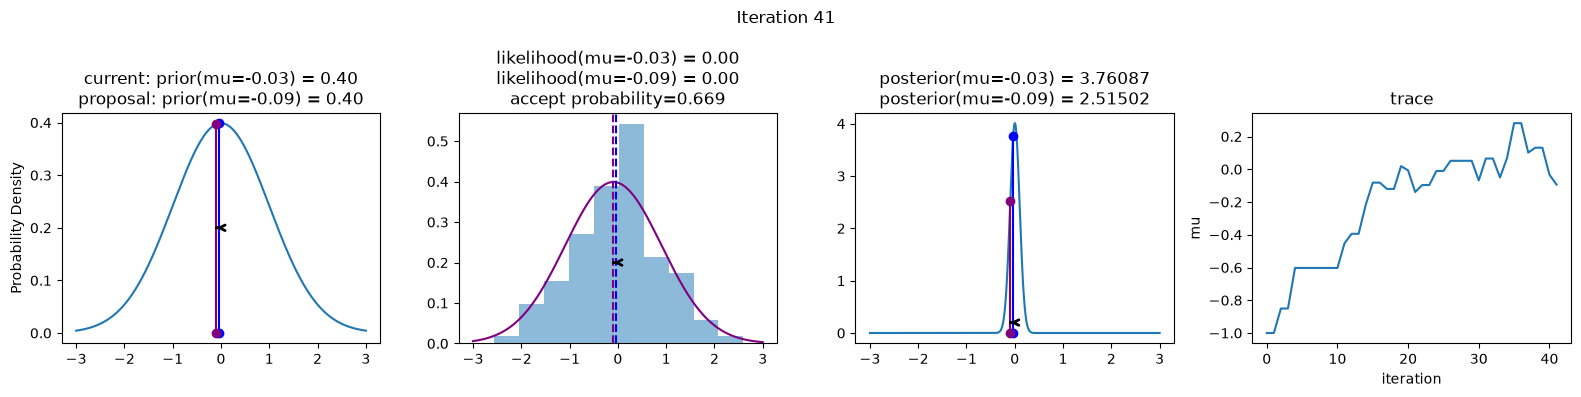

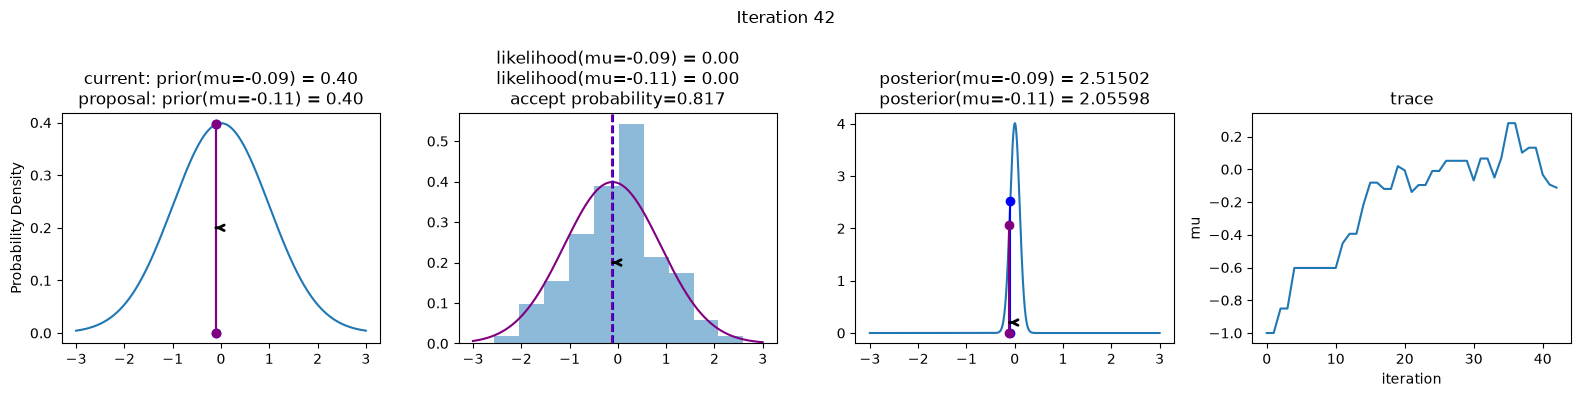

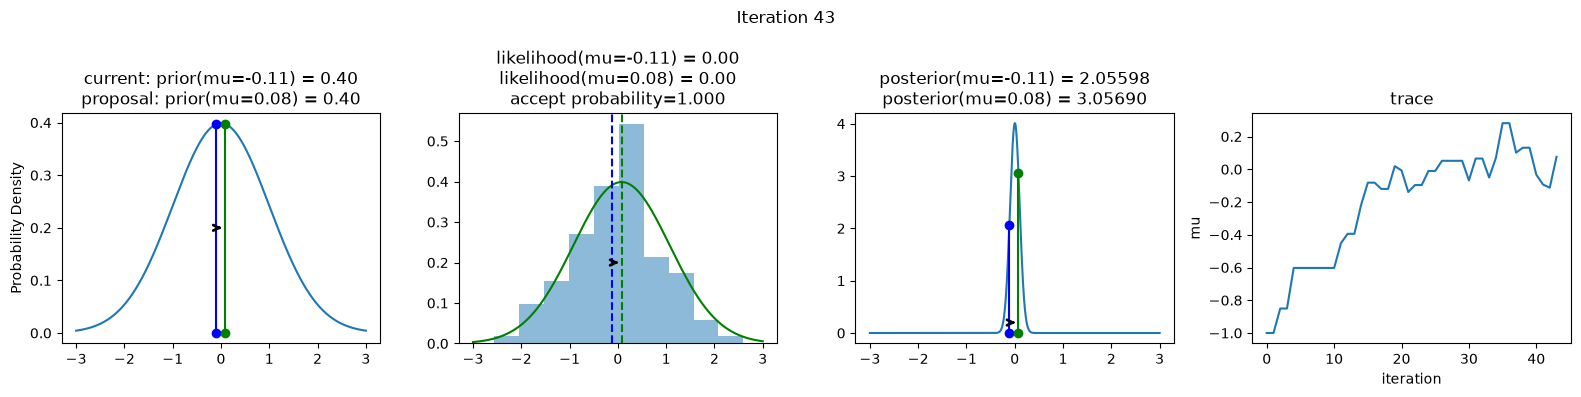

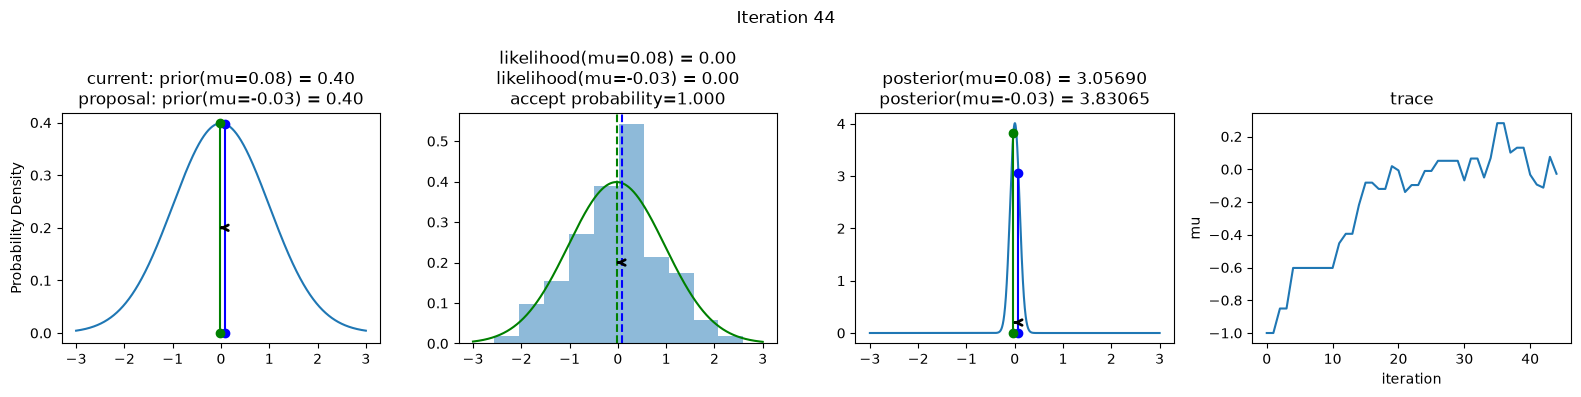

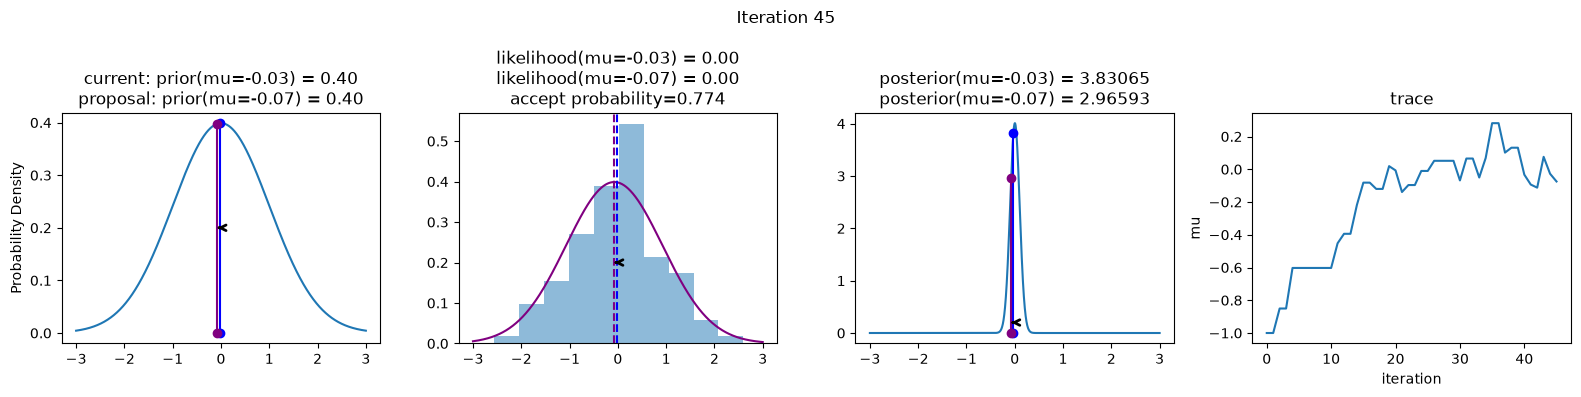

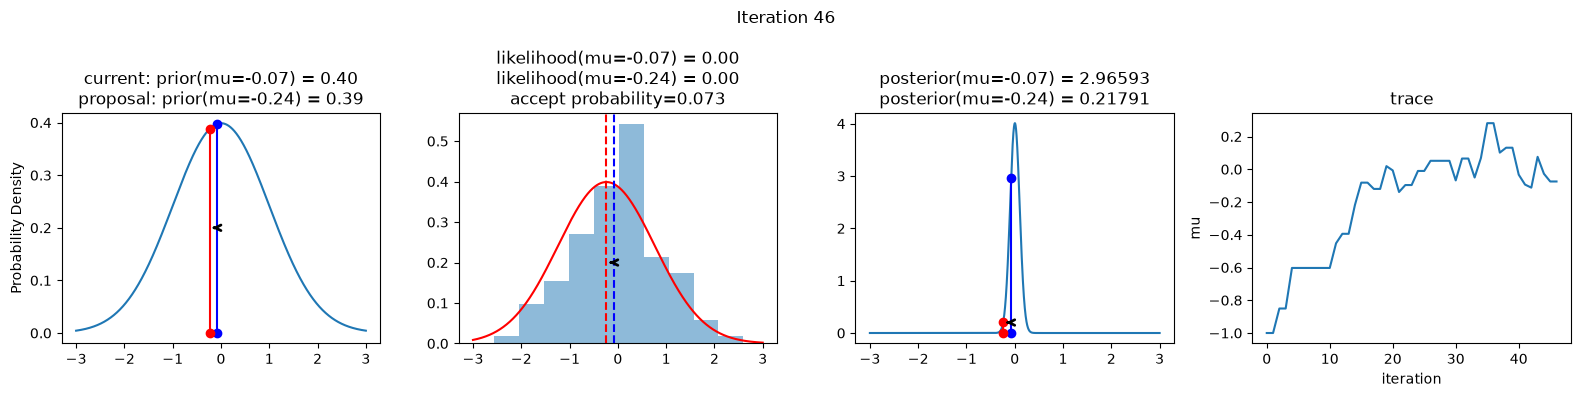

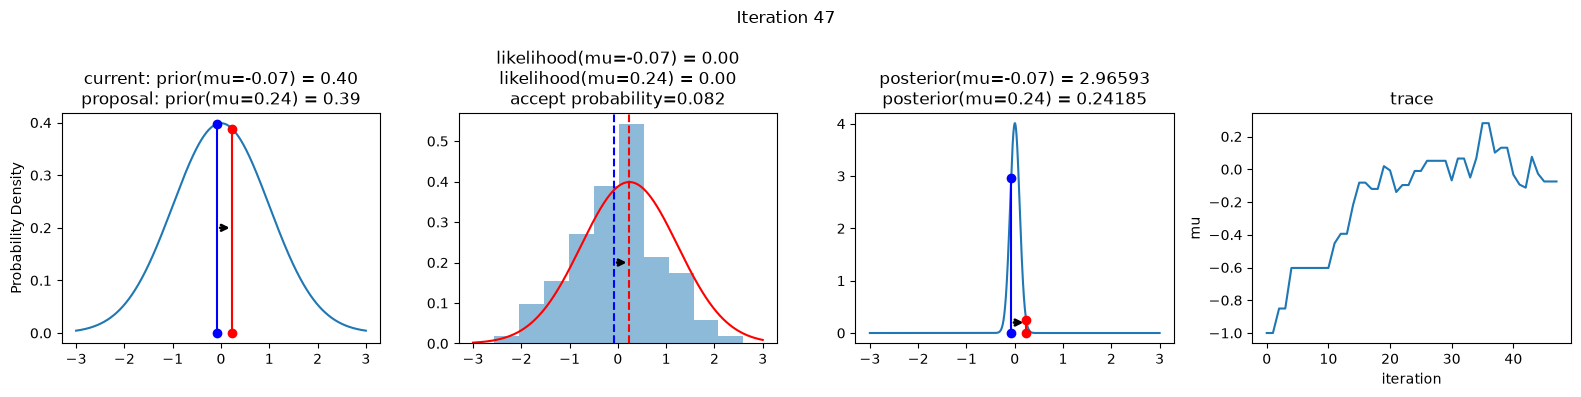

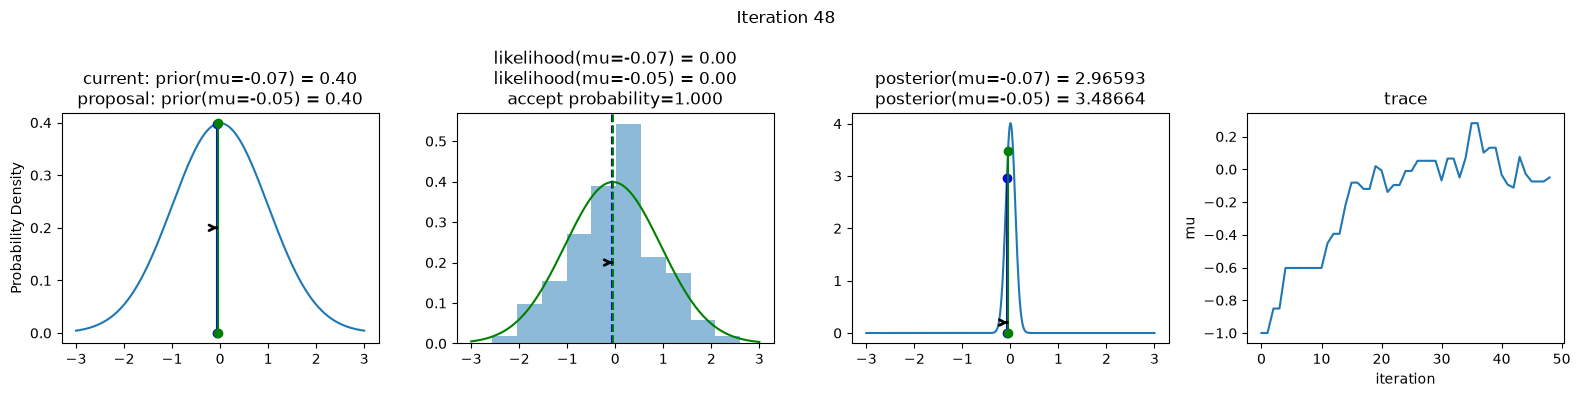

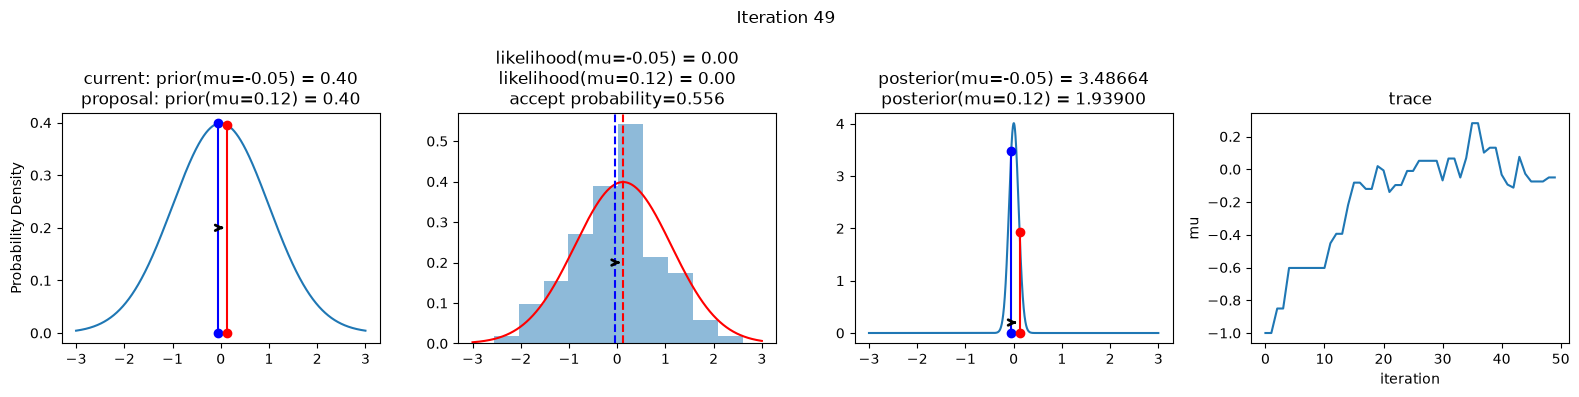

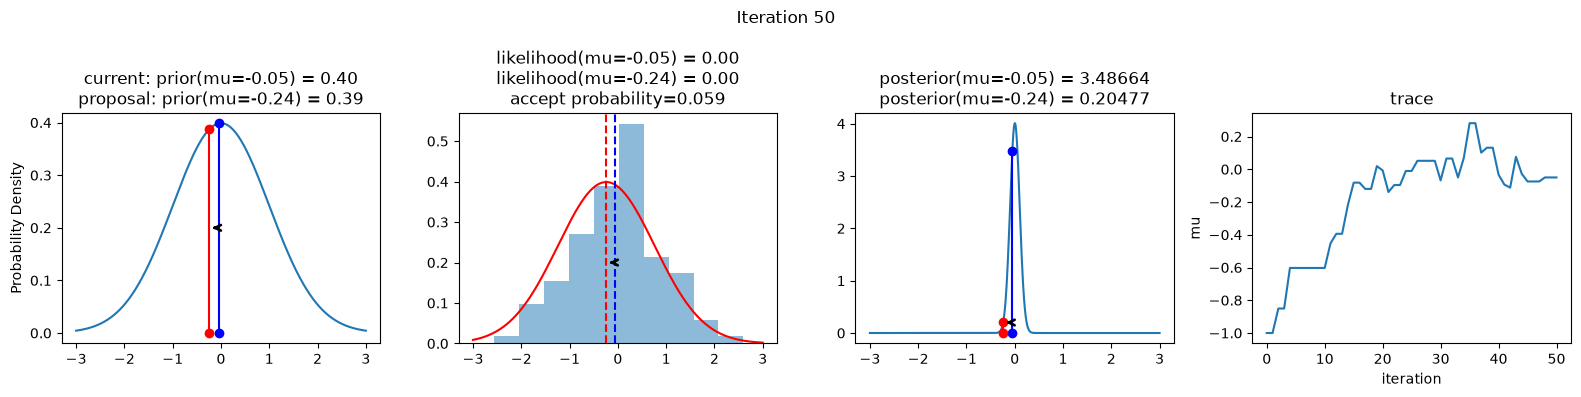

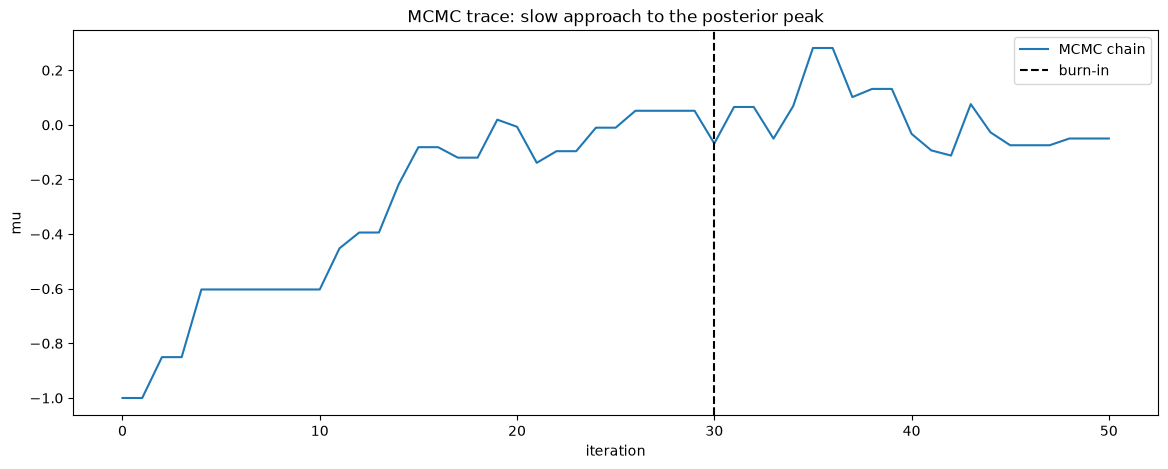

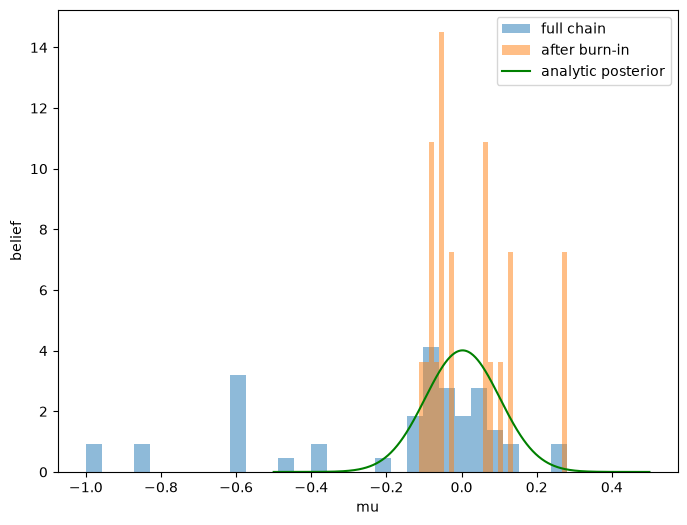

In [15]:
data = np.random.randn(100)
plt.figure(figsize=(8,8))
plt.hist(data)
plt.xlabel('x')
plt.ylabel('N')

#Execute this cell
def calc_posterior_analytical(data, xgrid, mu_0, sigma_0):
    sigma = 1.
    n = len(data)
    #Error-weighted sum of prior and average of data
    #Recall from lecture 3 the formula for the product of 2 Gaussians
    mu_post = (mu_0 / sigma_0**2 + data.sum() / sigma**2) / (1. / sigma_0**2 + n / sigma**2)
    # This is the Gaussian for the prior: mu_0 / sigma_0**2
    # This is the Gaussian for the likelihood: data.sum() / sigma**2
    # We are deriv/ing the mean from the sum of the data values
    var_post = (1. / sigma_0**2 + n / sigma**2)**-1
    return norm.pdf(xgrid, mu_post, np.sqrt(var_post))

plt.figure(figsize=(8,8))
xgrid = np.linspace(-1, 1, 500)
posterior_analytical = calc_posterior_analytical(data, xgrid, 0., 1.)
plt.plot(xgrid, posterior_analytical)
plt.xlabel('mu')
plt.ylabel('post prob')

# Execute this cell
# See https://github.com/twiecki/WhileMyMCMCGentlySamples/blob/master/content/downloads/notebooks/MCMC-sampling-for-dummies.ipynb

def sampler(data, samples=4, mu_init=.5, proposal_width=0.1, plot=False, mu_prior_mu=0, mu_prior_sd=1.):
    mu_current = mu_init
    posterior = [mu_current]
    for i in range(samples):
        # suggest a nearby value; a smaller proposal width makes the chain move more slowly.
        mu_proposal = norm(mu_current, proposal_width).rvs()

        # Compute likelihood by multiplying probabilities of each data point.
        likelihood_current = norm(mu_current, 1).pdf(data).prod()
        likelihood_proposal = norm(mu_proposal, 1).pdf(data).prod()

        # Compute prior probability of current and proposed mu.
        prior_current = norm(mu_prior_mu, mu_prior_sd).pdf(mu_current)
        prior_proposal = norm(mu_prior_mu, mu_prior_sd).pdf(mu_proposal)

        p_current = likelihood_current * prior_current
        p_proposal = likelihood_proposal * prior_proposal

        # Accept the proposal with probability min(1, p_proposal / p_current).
        # This allows occasional moves to worse values, which helps the chain explore the posterior.
        p_accept = min(1., p_proposal / p_current)
        accept = np.random.rand() < p_accept

        if plot:
            plot_proposal(mu_current, mu_proposal, mu_prior_mu, mu_prior_sd, data, accept, posterior, i, p_accept, p_current, p_proposal)

        if accept:
            mu_current = mu_proposal

        posterior.append(mu_current)

    return posterior


# Function to display

def plot_proposal(mu_current, mu_proposal, mu_prior_mu, mu_prior_sd, data, accepted, trace, i, p_accept, p_current, p_proposal):
    from copy import copy
    trace = copy(trace)
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols=4, figsize=(16, 4))
    fig.suptitle('Iteration %i' % (i + 1))
    xgrid = np.linspace(-3, 3, 5000)

    if accepted and p_proposal >= p_current:
        color = 'green'
    elif accepted:
        color = 'purple'
    else:
        color = 'red'

    # Plot prior
    prior_current = norm(mu_prior_mu, mu_prior_sd).pdf(mu_current)
    prior_proposal = norm(mu_prior_mu, mu_prior_sd).pdf(mu_proposal)
    prior = norm.pdf(xgrid, mu_prior_mu, mu_prior_sd)
    ax1.plot(xgrid, prior)
    ax1.plot([mu_current] * 2, [0, prior_current], marker='o', color='b')
    ax1.plot([mu_proposal] * 2, [0, prior_proposal], marker='o', color=color)
    ax1.annotate("", xy=(mu_proposal, 0.2), xytext=(mu_current, 0.2), arrowprops=dict(arrowstyle="->", lw=2.))
    ax1.set(ylabel='Probability Density', title='current: prior(mu=%.2f) = %.2f\nproposal: prior(mu=%.2f) = %.2f' % (mu_current, prior_current, mu_proposal, prior_proposal))

    # Likelihood
    likelihood_current = norm(mu_current, 1).pdf(data).prod()
    likelihood_proposal = norm(mu_proposal, 1).pdf(data).prod()
    y = norm.pdf(xgrid, loc=mu_proposal, scale=1)
    ax2.hist(data, alpha=0.5, density='True')
    ax2.plot(xgrid, y, color=color)
    ax2.axvline(mu_current, color='b', linestyle='--', label='mu_current')
    ax2.axvline(mu_proposal, color=color, linestyle='--', label='mu_proposal')
    ax2.annotate("", xy=(mu_proposal, 0.2), xytext=(mu_current, 0.2), arrowprops=dict(arrowstyle="->", lw=2.))
    ax2.set(title='likelihood(mu=%.2f) = %.2f\nlikelihood(mu=%.2f) = %.2f\naccept probability=%.3f' % (mu_current, 1e14*likelihood_current, mu_proposal, 1e14*likelihood_proposal, p_accept))

    # Posterior
    posterior_analytical = calc_posterior_analytical(data, xgrid, mu_prior_mu, mu_prior_sd)
    ax3.plot(xgrid, posterior_analytical)
    posterior_current = calc_posterior_analytical(data, mu_current, mu_prior_mu, mu_prior_sd)
    posterior_proposal = calc_posterior_analytical(data, mu_proposal, mu_prior_mu, mu_prior_sd)
    ax3.plot([mu_current] * 2, [0, posterior_current], marker='o', color='b')
    ax3.plot([mu_proposal] * 2, [0, posterior_proposal], marker='o', color=color)
    ax3.annotate("", xy=(mu_proposal, 0.2), xytext=(mu_current, 0.2), arrowprops=dict(arrowstyle="->", lw=2.))
    ax3.set(title='posterior(mu=%.2f) = %.5f\nposterior(mu=%.2f) = %.5f' % (mu_current, posterior_current, mu_proposal, posterior_proposal))

    if accepted:
        trace.append(mu_proposal)
    else:
        trace.append(mu_current)
    ax4.plot(trace)
    ax4.set(xlabel='iteration', ylabel='mu', title='trace')
    plt.tight_layout()


np.random.seed(123)
posterior = sampler(data, samples=50, mu_init=-1., proposal_width=0.15, plot=True)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(posterior, lw=1.5, label='MCMC chain')

burn = 30
ax.axvline(burn, color='k', ls='--', label='burn-in')

ax.set(
    xlabel='iteration',
    ylabel='mu',
    title='MCMC trace: slow approach to the posterior peak'
)
ax.legend()

plt.figure(figsize=(8, 6))

plt.hist(
    posterior,
    bins=30,
    alpha=0.5,
    density=True,
    label='full chain'
)

plt.hist(
    posterior[burn:],
    bins=30,
    alpha=0.5,
    density=True,
    label='after burn-in'
)

xplot = np.linspace(-.5, .5, 500)
post = calc_posterior_analytical(data, xplot, 0, 1)
plt.plot(xplot, post, 'g', label='analytic posterior')

plt.xlabel('mu')
plt.ylabel('belief')
plt.legend(fontsize=10)